In [ ]:
from app.services.entities import Passenger, Interval, Flight, ArrivalSampler
import app.services.predictive as predictive
import app.services.preprocessing as preprocessing
import app.services.samplers as samplers
import app.services.arrival_flow as arrival_flow
import app.services.security_class as security_class
import app.services.utils as utils
import app.services.plotting_utils as plotutils

import joblib
import datetime as dt
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import ast
import json
import requests
import asyncio
from io import BytesIO, StringIO
base_seed = 42

import logging
logging.basicConfig(level=logging.INFO, 
                    format="%(asctime)s | %(levelname)s | %(name)s | %(message)s",
                    force=True)

### ML

In [5]:
apt_iata = "FLR"
folder = os.path.join("data", "hist_schedule")

files = [
    os.path.join(folder, f)
    for f in os.listdir(folder)
    if f.endswith(".csv")
]

df = pd.concat(
    [pd.read_csv(file, sep=';', low_memory=False) for file in files],
    ignore_index=True
)

#filter schedule
df_f = df[(df['AVIAZIONE'] == 'Commerciale') & (df['NATURA'] == 'P') & (df['SCALO_TECNICO'] == 0) & (df['ADULT'] != 0) & (~df['NUMERO_MASSIMO_PAX'].isna()) & 
          ((df['ADULT']+df['CHILD']) <= df['NUMERO_MASSIMO_PAX'])]

df_f

,ID_VOLO,ID_LEGATO,DATA_VOLO,NOME_ESERCENTE,NAME_CARRIER,MATRICOLA_AEROMOBILE,PESO_MASSIMO,MODELLO_AEROMOBILE,NUMERO_MASSIMO_PAX,CODICE_ICAO,...,CERTIFICATO,ESPORTATO,GATE,VOLO_RISCHEDULATO,STATO_ATTIVITA,READY,CERT_TIMESTAMP,DATA_DIR_CANC,CAUSALE_DIR_CANC,MERCE_ESENTE
29,26808735,26808210.0,20170101,NaN,AIR FRANCE,FGUGI,60.0,A318,131.0,AFR,...,S,S,NaN,NaN,Completato,NaN,2017-01-02 08:56:31.000,NaN,NaN,NaN
30,26808742,26808231.0,20170101,NaN,KLM-ROYAL DUTCH AIRLINES,PHEZO,45.0,E190,100.0,KLM,...,S,S,NaN,NaN,Completato,NaN,2017-01-01 07:11:01.000,NaN,NaN,NaN
31,26808756,26808217.0,20170101,NaN,LUFTHANSA,DAECD,51.0,E190,94.0,DLH,...,S,S,NaN,NaN,Completato,NaN,2017-01-01 08:24:24.000,NaN,NaN,NaN
32,26808763,26808196.0,20170101,NaN,VUELING AIRLINES,ECMKV,64.0,A319,144.0,VLG,...,S,S,NaN,NaN,Completato,NaN,2017-01-01 09:31:49.000,NaN,NaN,NaN
33,26808770,26808189.0,20170101,NaN,SWISS,HBJVP,51.0,E190,110.0,SWR,...,S,S,NaN,NaN,Completato,NaN,2017-01-01 10:52:52.000,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
314323,68716698,68716533.0,20251218,NaN,ITA AIRWAYS,EIIMB,64.0,A319,144.0,ITY,...,S,S,GATE 1,NaN,Completato,NaN,2026-01-05 10:55:26.000,NaN,NaN,0.0
314427,68924169,68923996.0,20251208,NaN,AIR SERBIA,YUAPF,68.0,A319,144.0,ASL,...,S,S,GATE 11,NaN,Completato,NaN,2025-12-08 21:27:43.000,NaN,NaN,0.0
314477,69100636,64538481.0,20251205,NaN,VOLOTEA,ECNGL,66.0,A319,156.0,VOE,...,S,S,GATE 2,NaN,Completato,NaN,2025-12-09 08:57:58.000,NaN,NaN,0.0
314736,69688892,64545032.0,20251217,NaN,AIR FRANCE,FHZUX,64.0,BCS3,148.0,AFR,...,S,S,GATE 3,NaN,Completato,NaN,2025-12-17 12:40:04.000,NaN,NaN,0.0


In [6]:
def standardize_df(df):
    df=df.copy()

    col_mapping= {'DATA_PREVISTA': 'date', 'ORA_PREVISTA': 'schtime', 
                  'CODICE_IATA':'car', 'CODICE_ICAO': 'car_icao', 'NUMERO_VOLO': 'flt_n', 'DESTINAZIONE': 'apt', 
                  'MODELLO_AEROMOBILE': 'ac', 'NUMERO_MASSIMO_PAX':'seats', 'ADULT': 'adults', 'CHILD': 'children', 'NUM_BAGAGLI': 'luggage'}
    df = df[col_mapping.keys()].copy()
    df.rename(columns=col_mapping, inplace=True)

    df["date"] = pd.to_datetime(df["date"].astype("string"), format="%Y%m%d", errors="coerce")

    df['week_day']= df['date'].dt.day_name(locale='en_US')
    df['month'] = df['date'].dt.month_name(locale='en_US')
    df['year'] = df['date'].dt.year

    schtime = (
        df["schtime"]
        .astype("string")
        .str.replace(".0", "", regex=False)
        .str.strip()
        .str.zfill(4)
    )

    schtime_dt = pd.to_datetime(
        schtime,
        format="%H%M",
        errors="coerce"
    )

    df["schtime"] = schtime_dt.dt.strftime("%H:%M")

    hour_decimal = schtime_dt.dt.hour + schtime_dt.dt.minute / 60

    df["sin_hour"] = np.sin(2 * np.pi * hour_decimal / 24)
    df["cos_hour"] = np.cos(2 * np.pi * hour_decimal / 24)

    df["fdatetime"] = pd.to_datetime(
        df["date"].dt.strftime("%Y-%m-%d")
        + " "
        + df["schtime"],
        errors="coerce"
    )

    # Carrier code
    df["car"] = (
        df["car"]
        .fillna(df["car_icao"])
        .fillna("_")
        .astype("string")
        .str.strip()
        .str.upper()
        .replace("", "_")
    )

    df = df[df["car"] != "_"].copy()

    # Flight number
    df["flt_n"] = (
        df["flt_n"]
        .fillna("")
        .astype("string")
        .str.replace(".0", "", regex=False)
        .str.strip()
        .str.replace(" ", "", regex=False)
        .str.upper()
        .str.replace(r"^0+(?=.)", "", regex=True)
    )

    # nflt = carrier + flight number, con uno spazio
    df["nflt"] = df["car"] + " " + df["flt_n"]
    df.drop(columns=["car_icao", 'flt_n'], inplace=True)

    df["ac"] = (
        df["ac"]
        .fillna("_")
        .astype("string")
        .str.strip()
        .str.upper()
        .replace("", "_")
    )

    df['pax'] = df['adults'] + df['children']
    df["load_factor"] = df["pax"] / df["seats"]

    return df

df1 = standardize_df(df_f)
# remove covid years
df1 = df1[~df1['year'].isin([2020, 2021])].copy()
print(df1.shape)
df1

(102722, 18)


,date,schtime,car,apt,ac,seats,adults,children,luggage,week_day,month,year,sin_hour,cos_hour,fdatetime,nflt,pax,load_factor
29,2017-01-01,06:20,AF,CDG,A318,131.0,115,10,101,Sunday,January,2017,0.996195,-0.087156,2017-01-01 06:20:00,AF 1267,125,0.954198
30,2017-01-01,06:30,KL,AMS,E190,100.0,95,2,117,Sunday,January,2017,0.991445,-0.130526,2017-01-01 06:30:00,KL 1638,97,0.970000
31,2017-01-01,07:20,LH,FRA,E190,94.0,89,2,79,Sunday,January,2017,0.939693,-0.342020,2017-01-01 07:20:00,LH 319,91,0.968085
32,2017-01-01,08:50,VY,MAD,A319,144.0,89,5,36,Sunday,January,2017,0.737277,-0.675590,2017-01-01 08:50:00,VY 1506,94,0.652778
33,2017-01-01,09:50,LX,ZRH,E190,110.0,81,11,80,Sunday,January,2017,0.537300,-0.843391,2017-01-01 09:50:00,LX 1679,92,0.836364
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
314323,2025-12-18,11:10,AZ,FCO,A319,144.0,118,1,142,Thursday,December,2025,0.216440,-0.976296,2025-12-18 11:10:00,AZ 1678,119,0.826389
314427,2025-12-08,20:20,JU,BEG,A319,144.0,67,1,45,Monday,December,2025,-0.819152,0.573576,2025-12-08 20:20:00,JU 469,68,0.472222
314477,2025-12-05,18:40,V7,CTA,A319,156.0,124,7,11,Friday,December,2025,-0.984808,0.173648,2025-12-05 18:40:00,V7 1705,131,0.839744
314736,2025-12-17,12:20,AF,CDG,BCS3,148.0,122,4,82,Wednesday,December,2025,-0.087156,-0.996195,2025-12-17 12:20:00,AF 1367,126,0.851351


##### creazione base per futuri voli

In [57]:
def build_ac_lookup(
    df: pd.DataFrame,
    lookback_days: int = 730,
    min_flights: int = 10,
):
    """
    Costruisce i lookup usando solo gli ultimi `lookback_days` giorni di storico
    (default 2 anni), per riflettere flotta/rotte attuali, non quelle del 2017.
 
    Catena di fallback:
      seats:  nflt -> (car, ac) -> ac -> global
      ac:     nflt -> (car, apt) -> car -> global
 
    Il livello "nflt" (numero di volo specifico) e' il piu' preciso: uno stesso
    numero di volo tende a essere operato in modo consistente dallo stesso
    equipaggiamento/capacita' nel tempo.
    """
    df = df.copy()
    df["date"] = pd.to_datetime(df["date"])
 
    cutoff = df["date"].max() - pd.Timedelta(days=lookback_days)
    recent = df[df["date"] >= cutoff]
 
    valid = recent[["car", "apt", "ac", "seats", "nflt"]].dropna()
    valid = valid[valid["seats"] > 0]
 
    # --- capienza tipica per nflt (primo livello, il piu' specifico) ---
    nflt_seats_stats = (
        valid.groupby("nflt")["seats"]
        .agg(seats=lambda s: s.mode().iloc[0], n_flights="count")
        .reset_index()
    )
 
    seats_by_nflt = (
        nflt_seats_stats[nflt_seats_stats["n_flights"] >= min_flights]
        .set_index("nflt")["seats"]
        .astype(int)
    )
 
    # --- capienza tipica per car, ac (fallback) ---
    car_ac_stats = (
        valid.groupby(["car", "ac"])["seats"]
        .agg(seats=lambda s: s.mode().iloc[0], n_flights="count")
        .reset_index()
    )
 
    seats_by_car_ac = (
        car_ac_stats[car_ac_stats["n_flights"] >= min_flights]
        .set_index(["car", "ac"])["seats"]
        .astype(int)
    )
 
    # --- capacita' tipica per solo ac (fallback finale prima del globale) ---
    seats_by_ac = (
        valid.groupby("ac")["seats"]
        .agg(lambda s: s.mode().iloc[0])
        .astype(int)
    )
 
    # --- modello aereo piu' usato per nflt (primo livello, il piu' specifico) ---
    nflt_ac_counts = (
        valid.groupby(["nflt", "ac"])
        .size()
        .rename("n_flights")
        .reset_index()
    )
 
    nflt_totals = nflt_ac_counts.groupby("nflt")["n_flights"].transform("sum")
 
    ac_by_nflt = (
        nflt_ac_counts[nflt_totals >= min_flights]
        .sort_values("n_flights", ascending=False)
        .drop_duplicates(subset=["nflt"], keep="first")
        .set_index("nflt")["ac"]
    )
 
    # --- modello piu' usato per car, apt (fallback) ---
    route_counts = (
        valid.groupby(["car", "apt", "ac"])
        .size()
        .rename("n_flights")
        .reset_index()
    )
 
    route_totals = route_counts.groupby(["car", "apt"])["n_flights"].transform("sum")
 
    route_ac = (
        route_counts[route_totals >= min_flights]
        .sort_values("n_flights", ascending=False)
        .drop_duplicates(subset=["car", "apt"], keep="first")
        .set_index(["car", "apt"])["ac"]
    )
 
    # --- modello piu' usato per carrier (fallback finale prima del globale) ---
    carrier_counts = (
        valid.groupby(["car", "ac"])
        .size()
        .rename("n_flights")
        .reset_index()
    )
 
    carrier_totals = carrier_counts.groupby("car")["n_flights"].transform("sum")
 
    carrier_ac = (
        carrier_counts[carrier_totals >= min_flights]
        .sort_values("n_flights", ascending=False)
        .drop_duplicates(subset=["car"], keep="first")
        .set_index("car")["ac"]
    )
 
    # --- fallback globale ---
    global_ac = valid["ac"].mode().iloc[0]
    global_seats = valid["seats"].mode().iloc[0]
 
    return {
        "seats_by_nflt": seats_by_nflt,
        "seats_by_car_ac": seats_by_car_ac,
        "seats_by_ac": seats_by_ac,
        "ac_by_nflt": ac_by_nflt,
        "route_ac": route_ac,
        "carrier_ac": carrier_ac,
        "global_ac": global_ac,
        "global_seats": global_seats,
    }

In [58]:
ac_lookup_bundle = build_ac_lookup(df1)

save_path = os.path.join("data", apt_iata, "ac_lookup.joblib")
os.makedirs(os.path.dirname(save_path), exist_ok=True)
joblib.dump(ac_lookup_bundle, save_path)

['data\\FLR\\ac_lookup.joblib']

##### testing

                 pax          seats    load_factor
count  102722.000000  102722.000000  102722.000000
mean      101.434279     127.629349       0.792031
std        27.822603      23.002886       0.162514
min         1.000000       6.000000       0.006944
5%         52.000000      94.000000       0.455133
25%        85.000000     112.000000       0.713115
50%       102.000000     131.000000       0.833333
75%       123.000000     144.000000       0.910000
95%       142.000000     156.000000       0.979167
99%       150.000000     180.000000       1.000000
max       174.000000     189.000000       1.000000


Text(0.5, 1.0, 'Distribution of pax per flight')

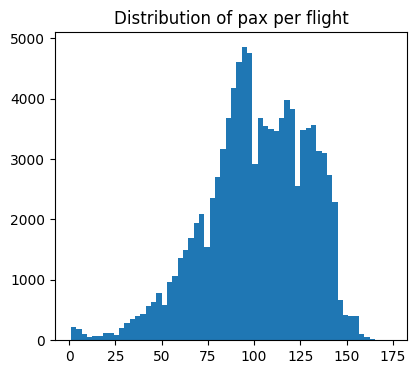

In [7]:
# outliers in pax e luaggage
print(df1[["pax", "seats", "load_factor"]].describe(
    percentiles=[0.05, 0.25, 0.5, 0.75, 0.95, 0.99]))

plt.figure(figsize=(10,4))
plt.subplot(121)
hist = plt.hist(df1["pax"], bins=60)
plt.title("Distribution of pax per flight")

In [8]:
from xgboost import XGBRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, root_mean_squared_error

def regression_report(y_true, y_pred, title=""):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    mae = mean_absolute_error(y_true, y_pred)
    rmse = root_mean_squared_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)

    mask = y_true != 0
    mape = (
        np.mean(
            np.abs(
                (y_true[mask] - y_pred[mask]) / y_true[mask]
            )
        ) * 100
    )

    wape = (
        np.sum(np.abs(y_true - y_pred))
        / np.sum(np.abs(y_true))
        * 100
    )

    print(title)
    print(f"MAE: {mae:.2f}")
    print(f"MAPE: {mape:.2f} %")
    print(f"RMSE: {rmse:.2f}")
    print(f"WAPE: {wape:.2f} %")
    print(f"R2: {r2:.3f}")

In [9]:
def baseline_model(train, val):

    train = train.copy()
    val = val.copy()

    global_lf = train["pax"].mean()

    mean_full = (
        train
        .groupby(["car", "apt", "ac", "month"])["pax"]
        .mean()
        .rename("pred_pax")
    )

    mean_car_apt_month = (
        train
        .groupby(["car", "apt", "month"])["pax"]
        .mean()
        .rename("pred_pax")
    )

    mean_car_apt = (
        train
        .groupby(["car", "apt"])["pax"]
        .mean()
        .rename("pred_pax")
    )

    mean_car = (
        train
        .groupby("car")["pax"]
        .mean()
        .rename("pred_pax")
    )

    out = val.copy()

    # livello più specifico
    out = out.merge(
        mean_full,
        on=["car", "apt", "ac", "month"],
        how="left"
    )

    # fallback car + apt + month
    fallback = out.merge(
        mean_car_apt_month,
        on=["car", "apt", "month"],
        how="left",
        suffixes=("", "_fallback")
    )

    out["pred_pax"] = out["pred_pax"].fillna(
        fallback["pred_pax_fallback"]
    )

    # fallback car + apt
    fallback = out.merge(
        mean_car_apt,
        on=["car", "apt"],
        how="left",
        suffixes=("", "_fallback")
    )

    out["pred_pax"] = out["pred_pax"].fillna(
        fallback["pred_pax_fallback"]
    )

    # fallback carrier
    fallback = out.merge(
        mean_car,
        on="car",
        how="left",
        suffixes=("", "_fallback")
    )

    out["pred_pax"] = out["pred_pax"].fillna(
        fallback["pred_pax_fallback"]
    )

    # ultimo fallback: media globale
    out["pred_pax"] = out["pred_pax"].fillna(global_lf)

    return out

In [10]:
# validation 2024 baseline model

# split
df = df1.copy()
df = df.sort_values("fdatetime").copy()

train_idx = df["year"] < 2024
val_idx = df["year"] == 2024

train = df.loc[train_idx].copy()
val = df.loc[val_idx].copy()

val_baseline = baseline_model(train, val)

regression_report(val["pax"], val_baseline["pred_pax"], "#Baseline Validation 2024")

#Baseline Validation 2024
MAE: 13.64
MAPE: 15.62 %
RMSE: 17.88
WAPE: 12.50 %
R2: 0.508


In [11]:
# test 2025 baseline model

# split
df = df1.copy()
df = df.sort_values("fdatetime").copy()

train_idx = df["year"] < 2025
val_idx = df["year"] == 2025

train = df.loc[train_idx].copy()
val = df.loc[val_idx].copy()

val_baseline = baseline_model(train, val)

regression_report(val["pax"], val_baseline["pred_pax"], "#Baseline Test 2025")

#Baseline Test 2025
MAE: 14.31
MAPE: 74.57 %
RMSE: 20.84
WAPE: 13.33 %
R2: 0.443


In [12]:
# validation 2024 XGBoost 

# split
df = df1.copy()
df = df.sort_values("fdatetime").copy()

train_idx = df["year"] < 2024
val_idx = df["year"] == 2024

train = df.loc[train_idx].copy()
val = df.loc[val_idx].copy()

features = ["month", "week_day", "sin_hour", "cos_hour", "car", "seats", "apt", "ac"]
target = "pax"

apt_column = ["apt"]
other_categorical_columns = ["month", "week_day", "car", "ac"]
numeric_columns = ["sin_hour", "cos_hour", "seats"]

X_train = train[features].copy()
X_val = val[features].copy()

y_train = train[target]
y_val = val[target]

# Airport encoder:
apt_encoder = OneHotEncoder(
    handle_unknown="infrequent_if_exist",
    min_frequency=50,
    sparse_output=False,
)
# Other categorical variables
other_encoder = OneHotEncoder(
    handle_unknown="infrequent_if_exist",
    min_frequency=100,
    sparse_output=False,
)

# Fit on training data
apt_encoder.fit(X_train[apt_column])
other_encoder.fit(X_train[other_categorical_columns])

# Transform airport
X_train_apt = apt_encoder.transform(X_train[apt_column])
X_val_apt = apt_encoder.transform(X_val[apt_column])

# Transform other categoricals
X_train_other = other_encoder.transform(X_train[other_categorical_columns])
X_val_other = other_encoder.transform(X_val[other_categorical_columns])

# Column names
apt_names = apt_encoder.get_feature_names_out(apt_column)
other_names = other_encoder.get_feature_names_out(other_categorical_columns)

# Assemble
X_train = pd.concat(
    [X_train[numeric_columns].reset_index(drop=True),
     pd.DataFrame(X_train_apt, columns=apt_names),
     pd.DataFrame(X_train_other, columns=other_names),
    ], axis=1,
)

X_val = pd.concat(
    [X_val[numeric_columns].reset_index(drop=True),
     pd.DataFrame(X_val_apt, columns=apt_names),
     pd.DataFrame(X_val_other, columns=other_names),
    ], axis=1,
)

xgb_pax = XGBRegressor(
    objective="reg:squarederror",
    random_state=10,
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=7,
    subsample=0.5,
    colsample_bytree=0.8,
    min_child_weight=5,
    n_jobs=-1,
)

xgb_pax.fit(X_train, y_train)

pax_pred_val = xgb_pax.predict(X_val)
pax_pred_val = np.rint(pax_pred_val).astype(int)

regression_report(val["pax"], pax_pred_val, "# XGBoost Validation PAX 2024")

# XGBoost Validation PAX 2024
MAE: 12.56
MAPE: 13.71 %
RMSE: 16.36
WAPE: 11.51 %
R2: 0.588


In [13]:
# test 2025 XGBoost 

# split
df = df1.copy()
df = df.sort_values("fdatetime").copy()

train_idx = df["year"] < 2025
val_idx = df["year"] == 2025

train = df.loc[train_idx].copy()
val = df.loc[val_idx].copy()

features = ["month", "week_day", "sin_hour", "cos_hour", "car", "seats", "apt", "ac"]
target = "pax"

apt_column = ["apt"]
other_categorical_columns = ["month", "week_day", "car", "ac"]
numeric_columns = ["sin_hour", "cos_hour", "seats"]

X_train = train[features].copy()
X_val = val[features].copy()

y_train = train[target]
y_val = val[target]

# Airport encoder:
apt_encoder = OneHotEncoder(
    handle_unknown="infrequent_if_exist",
    min_frequency=50,
    sparse_output=False,
)
# Other categorical variables
other_encoder = OneHotEncoder(
    handle_unknown="infrequent_if_exist",
    min_frequency=100,
    sparse_output=False,
)

# Fit on training data
apt_encoder.fit(X_train[apt_column])
other_encoder.fit(X_train[other_categorical_columns])

# Transform airport
X_train_apt = apt_encoder.transform(X_train[apt_column])
X_val_apt = apt_encoder.transform(X_val[apt_column])

# Transform other categoricals
X_train_other = other_encoder.transform(X_train[other_categorical_columns])
X_val_other = other_encoder.transform(X_val[other_categorical_columns])

# Column names
apt_names = apt_encoder.get_feature_names_out(apt_column)
other_names = other_encoder.get_feature_names_out(other_categorical_columns)

# Assemble
X_train = pd.concat(
    [X_train[numeric_columns].reset_index(drop=True),
     pd.DataFrame(X_train_apt, columns=apt_names),
     pd.DataFrame(X_train_other, columns=other_names),
    ], axis=1,
)

X_val = pd.concat(
    [X_val[numeric_columns].reset_index(drop=True),
     pd.DataFrame(X_val_apt, columns=apt_names),
     pd.DataFrame(X_val_other, columns=other_names),
    ], axis=1,
)

xgb_pax = XGBRegressor(
    objective="reg:squarederror",
    random_state=10,
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=7,
    subsample=0.5,
    colsample_bytree=0.8,
    min_child_weight=5,
    n_jobs=-1,
)

xgb_pax.fit(X_train, y_train)

pax_pred_val = xgb_pax.predict(X_val)
pax_pred_val = np.rint(pax_pred_val).astype(int)

regression_report(val["pax"], pax_pred_val, "# XGBoost Test PAX 2025")

# XGBoost Test PAX 2025
MAE: 11.74
MAPE: 17.36 %
RMSE: 15.76
WAPE: 10.93 %
R2: 0.682


<Axes: title={'center': 'Feature importance'}, xlabel='Importance score', ylabel='Features'>

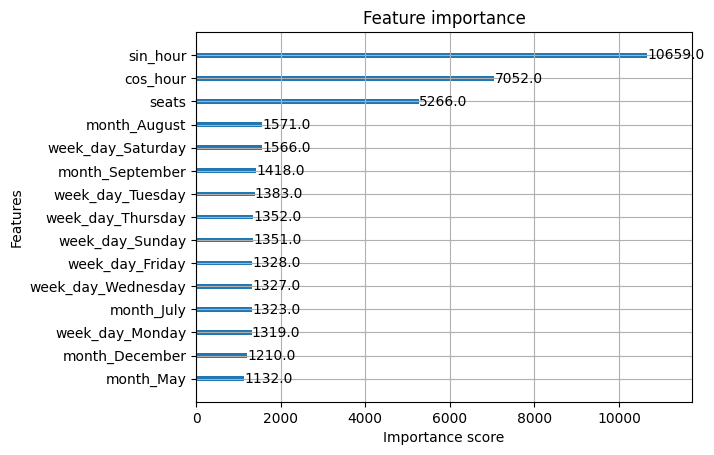

In [14]:
from xgboost import plot_importance
plot_importance(xgb_pax, max_num_features=15)

##### training for production

In [16]:
# training fino al 2025 incluso

df = df1.copy()
df = df.sort_values("fdatetime").copy()

train_idx = df["year"] < 2026
train = df.loc[train_idx].copy()

features = ["month", "week_day", "sin_hour", "cos_hour", "car", "seats", "apt", "ac"]
target = "pax"

apt_column = ["apt"]
other_categorical_columns = ["month", "week_day", "car", "ac"]
numeric_columns = ["sin_hour", "cos_hour", "seats"]

X_train = train[features].copy()
y_train = train[target]

# Airport encoder:
apt_encoder = OneHotEncoder(
    handle_unknown="infrequent_if_exist",
    min_frequency=50,
    sparse_output=False,
)
# Other categorical variables
other_encoder = OneHotEncoder(
    handle_unknown="infrequent_if_exist",
    min_frequency=100,
    sparse_output=False,
)

# Fit on training data
apt_encoder.fit(X_train[apt_column])
other_encoder.fit(X_train[other_categorical_columns])

# Transform airport
X_train_apt = apt_encoder.transform(X_train[apt_column])

# Transform other categoricals
X_train_other = other_encoder.transform(X_train[other_categorical_columns])

# Column names
apt_names = apt_encoder.get_feature_names_out(apt_column)
other_names = other_encoder.get_feature_names_out(other_categorical_columns)

# Assemble
X_train = pd.concat(
    [X_train[numeric_columns].reset_index(drop=True),
     pd.DataFrame(X_train_apt, columns=apt_names),
     pd.DataFrame(X_train_other, columns=other_names),
    ], axis=1,
)

xgb_pax = XGBRegressor(
    objective="reg:squarederror",
    random_state=10,
    n_estimators=1000,
    learning_rate=0.03,
    max_depth=7,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=5,
    n_jobs=-1,
)

xgb_pax.fit(X_train, y_train)

# save model and encoders

import joblib

model_bundle = {
    "model": xgb_pax,
    "apt_encoder": apt_encoder,
    "other_encoder": other_encoder,
    "features": features,
    "apt_column": apt_column,
    "other_categorical_columns": other_categorical_columns,
    "numeric_columns": numeric_columns,
    "target": "pax",
}

joblib.dump(
    model_bundle,
    f"data/pax_model.joblib",
)

['data/pax_model.joblib']

### arrival curves

In [37]:
# entire schedule
apt_iata= 'FLR'

url = f"https://aosnice-api.toscana-aeroporti.com/{apt_iata}/getPlannedFlights"
response = requests.get(url)
response.raise_for_status()
data = response.json()
flights = data["RESPONSE"]["result"]["elements"]

rows = []
for f in flights:
    rows.append({
        "flight_number": f.get("number"),
        "nature": f.get("nature", {}).get("code"),
        "carrier": f.get("carrier", {}).get("publicCode"),
        "airport": f.get("airport", {}).get("code"),
        "periods": f.get("periods", [])
    })

all_flights = pd.DataFrame(rows)

# filter departures and explode periods
sched = all_flights[all_flights["nature"] == "P"].drop(columns=["nature"]).rename(columns={"airport": "apt"}).copy()
sched["periods"] = sched["periods"].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) else x)
sched = (
    sched
    .explode("periods", ignore_index=True)
    .join(pd.json_normalize(sched.explode("periods")["periods"]))
    .drop(columns=["periods"])
)

sched["from"] = pd.to_datetime(sched["from"]).dt.normalize()
sched["to"] = pd.to_datetime(sched["to"]).dt.normalize()
sched["flight_number"] = (sched["flight_number"].astype(str).str.replace(r"\.0$", "", regex=True).str.lstrip("0"))
sched["freq"] = sched["frequency"].str.split(",")
sched.to_csv(os.path.join('data', 'schedule_all.csv'), index=False)

In [40]:
# security data
df_security = pd.read_csv(os.path.join('data', 'security_arrivals.csv'), sep=';')
df_security = df_security[
    (df_security['LAST_POSITION'] == 'SECURITY_AREA') &
    (df_security['PASSAGE_AUTHORIZED'] == 1)
].copy()

df_security["FLIGHT_NUMBER"] = df_security["FLIGHT_NUMBER"].astype(str).str.lstrip("0")
df_security["DATE_OF_FLIGHT"] = pd.to_datetime(df_security["DATE_OF_FLIGHT"]).dt.normalize()
df_security["SCR_TIME"] = pd.to_datetime(df_security["SCR_TIME"], errors="coerce")

df_security = (
    df_security
    .sort_values('SCR_TIME')
    .drop_duplicates(subset='ID', keep='last')
    .reset_index(drop=True)
)

cols_to_keep = ['ID', 'DATE_OF_FLIGHT', 'OPERATING_CARRIER', 'FLIGHT_NUMBER', 'SCR_TIME']
df_security = df_security[cols_to_keep].copy()
df_security["weekday"] = df_security["DATE_OF_FLIGHT"].dt.isocalendar().day

C:\Users\zanch\AppData\Local\Temp\ipykernel_21712\4287610874.py:2: DtypeWarning: Columns (5) have mixed types. Specify dtype option on import or set low_memory=False.
  df_security = pd.read_csv(os.path.join('data', 'security_arrivals.csv'), sep=';')


In [42]:
# merge
sched = pd.read_csv(os.path.join('data', 'schedule_all.csv'))
sched['flight_number'] = sched['flight_number'].astype(str)

out = df_security.merge(
    sched,
    left_on=["OPERATING_CARRIER", "FLIGHT_NUMBER"],
    right_on=["carrier", "flight_number"],
    how="left"
).drop(columns=["carrier", "flight_number"])
out["frequency"] = out["frequency"].fillna("")

mask = (
    out["DATE_OF_FLIGHT"].between(out["from"], out["to"])
    &
    out.apply(
        lambda r: str(r["weekday"]) in r["frequency"].split(","),
        axis=1
    )
)

out = out[mask].copy()

out["SCR_TIME"] = pd.to_datetime(out["SCR_TIME"], errors="coerce")
out["time"] = pd.to_datetime(out["time"], errors="coerce")
out['flight_number'] = out['OPERATING_CARRIER'] + ' ' + out['FLIGHT_NUMBER']

out["departure_dt"] = (
    out["DATE_OF_FLIGHT"]
    + pd.to_timedelta(out["time"].dt.hour, unit="h")
    + pd.to_timedelta(out["time"].dt.minute, unit="m")
    + pd.to_timedelta(out["time"].dt.second, unit="s")
)

out["advance"] = (out["departure_dt"] - out["SCR_TIME"]).dt.total_seconds() / 60

out["month"] = out["departure_dt"].dt.month_name(locale="en_US")
out["departure_hour"] = out["departure_dt"].dt.hour
out["time_band"] = pd.cut(
    out["departure_hour"],
    bins=[-1, 5, 9, 13, 17, 21, 23],
    labels=[
        "00-05",
        "06-09",
        "10-13",
        "14-17",
        "18-21",
        "22-23",
    ]
)
out.rename(columns={"OPERATING_CARRIER": "car"}, inplace=True)

out["advance"].describe(percentiles=[0.01, 0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99])

count    304311.000000
mean        105.636527
std          35.450038
min        -561.066667
1%           30.936667
5%           52.700000
10%          62.983333
25%          81.200000
50%         103.550000
75%         129.083333
90%         154.983333
95%         168.650000
99%         178.700000
max         347.183333
Name: advance, dtype: float64

In [43]:
# clean outliers
p5 = out["advance"].quantile(0.05)
p99 = out["advance"].quantile(0.999)

df_arrivals_clean = out[(out["advance"] <= p99) & (out["advance"] >= p5)].copy()

print(f"soglia p5: {p5:.1f} min")
print(f"soglia p99: {p99:.1f} min")
print("righe totali:", len(out))
print("righe rimosse:", len(out) - len(df_arrivals_clean))
print("righe rimanenti:", len(df_arrivals_clean))

soglia p5: 52.7 min
soglia p99: 201.5 min
righe totali: 304311
righe rimosse: 15512
righe rimanenti: 288799


#### test vari

In [44]:
def advance_summary(df, group_cols, min_count=100):

    summary = (
        df.groupby(group_cols)["advance"]
        .agg(
            count="count",
            mean="mean",
            median="median",
            std="std",
            p05=lambda x: x.quantile(0.05),
            p25=lambda x: x.quantile(0.25),
            p75=lambda x: x.quantile(0.75),
            p95=lambda x: x.quantile(0.95),
        )
        .reset_index()
    )

    summary = summary[
        summary["count"] >= min_count
    ].copy()

    return summary.sort_values(
        "median",
        ascending=False
    )

def plot_boxplot(df, group_col, min_count=100, top_n=20):
    counts = df[group_col].value_counts()

    if isinstance(df[group_col].dtype, pd.CategoricalDtype):
        valid_groups = [
            g for g in df[group_col].cat.categories
            if counts.get(g, 0) >= min_count
        ]
    else:
        valid_groups = counts[counts >= min_count].index.tolist()

    valid_groups = valid_groups[:top_n]

    data = [
        df.loc[df[group_col] == g, "advance"].dropna()
        for g in valid_groups
    ]

    plt.figure(figsize=(12, 6))

    plt.boxplot(
        data,
        tick_labels=valid_groups,
        showfliers=True,
        flierprops={
            "marker": "o",
            "markersize": 1,
            "alpha": 0.5,
            "markeredgewidth": 1,
        }
    )

    plt.ylabel("Minutes before departure")
    plt.xlabel(group_col)
    plt.title(f"Security advance by {group_col}")

    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

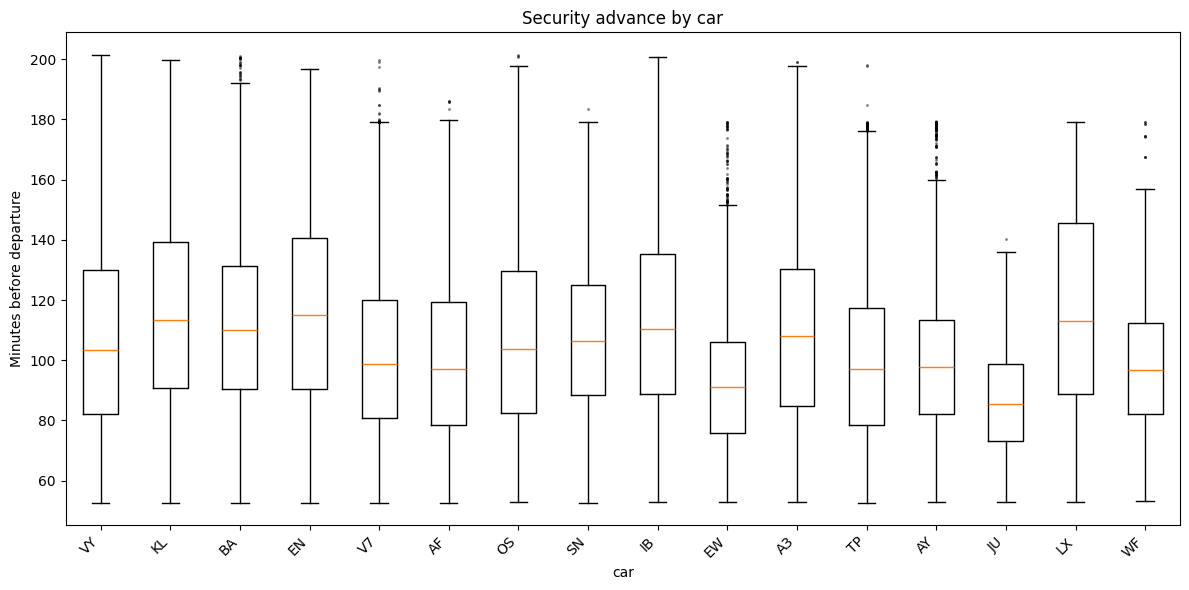

In [45]:
by_carrier = plot_boxplot(
    df_arrivals_clean,
    "car"
)

by_carrier

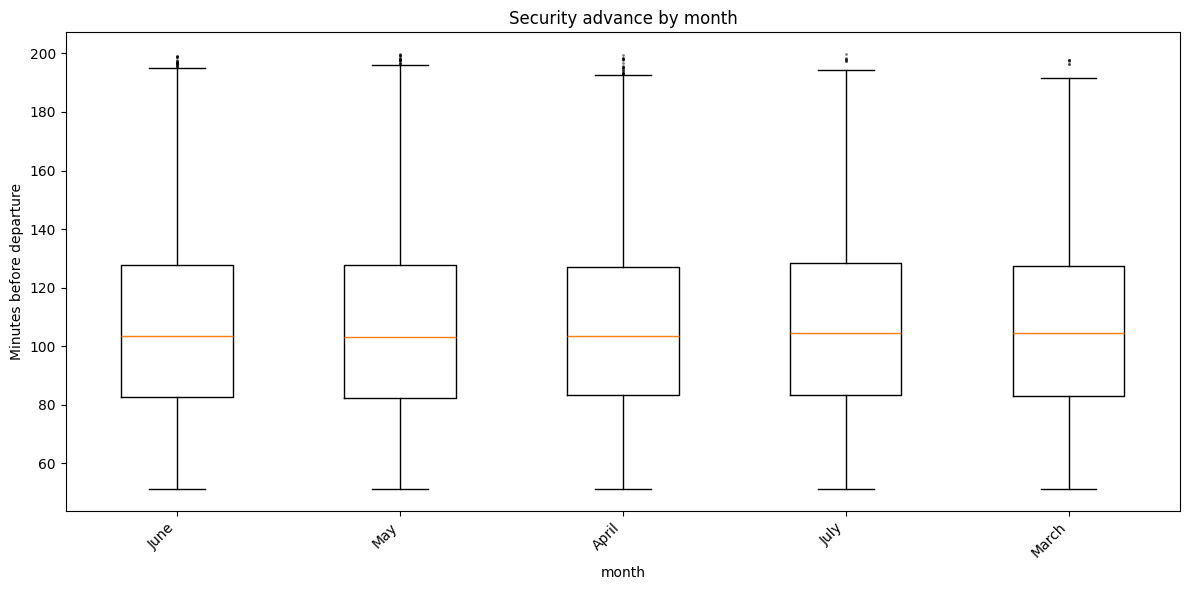

In [85]:
by_month = plot_boxplot(
    df_arrivals_clean,
    "month"
)

by_month

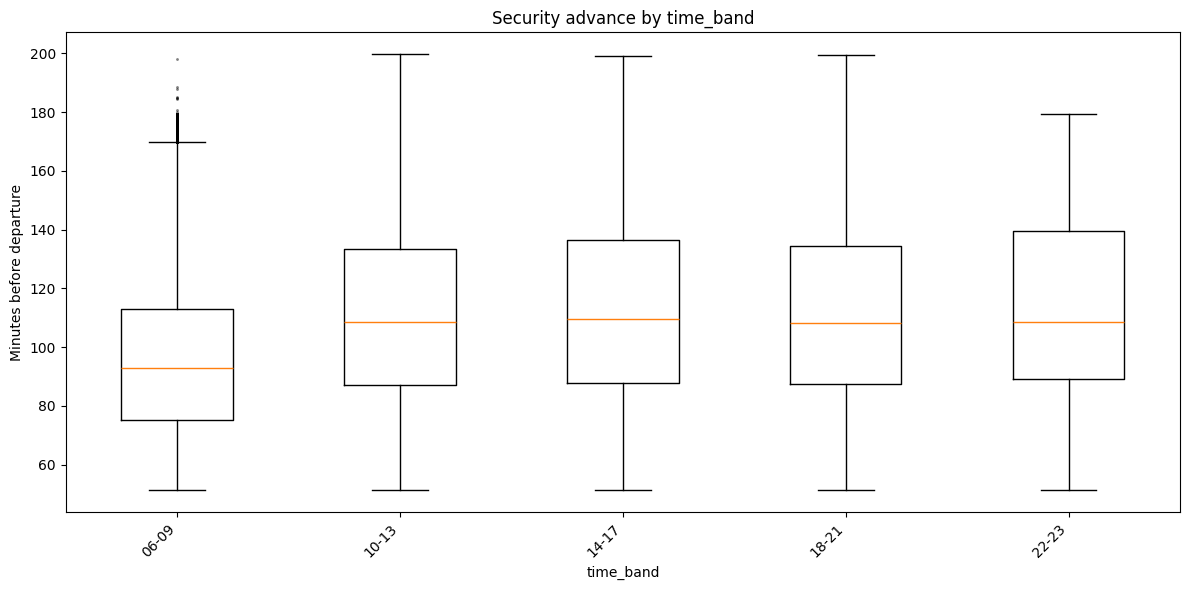

In [86]:
by_time = plot_boxplot(
    df_arrivals_clean,
    "time_band",
    min_count=1
)
by_time

#### normalizing flows

In [46]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import zuko

torch.manual_seed(42)
np.random.seed(42)

df_nf = df_arrivals_clean.copy()
df_nf["log_advance"] = np.log(df_nf["advance"])

cat_cols = ["car", "month", "time_band", "apt"]
MIN_FREQ = 10

code_lookup = {}
cardinalities = {}

for col in cat_cols:
    counts = df_nf[col].value_counts()
    keep = set(counts[counts >= MIN_FREQ].index)
    categories = sorted(keep) + ["UNK"]
    lookup = {cat: i for i, cat in enumerate(categories)}

    df_nf[col + "_code"] = df_nf[col].where(df_nf[col].isin(keep), "UNK").map(lookup)
    code_lookup[col] = lookup
    cardinalities[col] = len(categories)

print("cardinalità (incluso UNK):", cardinalities)

# split per volo
df_nf["flight_key"] = df_nf["flight_number"] + "_" + df_nf["DATE_OF_FLIGHT"].astype(str)

unique_flights = df_nf["flight_key"].unique()
rng = np.random.default_rng(42)
rng.shuffle(unique_flights)

n_val = int(0.15 * len(unique_flights))
val_flights = set(unique_flights[:n_val])
df_nf["is_val"] = df_nf["flight_key"].isin(val_flights)

train_df = df_nf[~df_nf["is_val"]].reset_index(drop=True)
val_df = df_nf[df_nf["is_val"]].reset_index(drop=True)

# standardizzazione log_advance (mean=0, std=1)
log_adv_mean = train_df["log_advance"].mean()
log_adv_std = train_df["log_advance"].std()

train_df["log_advance_std"] = (train_df["log_advance"] - log_adv_mean) / log_adv_std
val_df["log_advance_std"] = (val_df["log_advance"] - log_adv_mean) / log_adv_std

code_cols = [c + "_code" for c in cat_cols]

class AdvanceDataset(Dataset):
    def __init__(self, frame):
        self.y = torch.tensor(frame["log_advance_std"].to_numpy(), dtype=torch.float32).unsqueeze(-1)
        self.cats = torch.tensor(frame[code_cols].to_numpy(), dtype=torch.long)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.y[idx], self.cats[idx]

train_loader = DataLoader(AdvanceDataset(train_df), batch_size=1024, shuffle=True)
val_loader = DataLoader(AdvanceDataset(val_df), batch_size=4096, shuffle=False)

cardinalità (incluso UNK): {'car': 17, 'month': 6, 'time_band': 6, 'apt': 26}


In [47]:
class Embedder(nn.Module):
    def __init__(self, cardinalities, embed_dim=8):
        super().__init__()
        self.embeddings = nn.ModuleList([
            nn.Embedding(card, embed_dim) for card in cardinalities.values()
        ])

    def forward(self, cats):
        parts = [emb(cats[:, i]) for i, emb in enumerate(self.embeddings)]
        return torch.cat(parts, dim=-1)

embed_dim = 8
embedder = Embedder(cardinalities, embed_dim=embed_dim)
context_dim = embed_dim * len(cat_cols)

flow = zuko.flows.NSF(
    features=1,
    context=context_dim,
    transforms=3,
    hidden_features=(64, 64),
)

optimizer = torch.optim.Adam(
    list(embedder.parameters()) + list(flow.parameters()),
    lr=1e-3,
)

def run_epoch(loader, train=True):
    embedder.train(train)
    flow.train(train)
    total_loss, n = 0.0, 0

    for y, cats in loader:
        context = embedder(cats)
        dist = flow(context)
        loss = -dist.log_prob(y).mean()

        if train:
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        total_loss += loss.item() * len(y)
        n += len(y)

    return total_loss / n

best_val = float("inf")
patience, bad_epochs = 8, 0
best_state = None

for epoch in range(200):
    train_nll = run_epoch(train_loader, train=True)
    with torch.no_grad():
        val_nll = run_epoch(val_loader, train=False)

    print(f"epoch {epoch+1:03d}  train NLL {train_nll:.4f}  val NLL {val_nll:.4f}")

    if val_nll < best_val:
        best_val = val_nll
        bad_epochs = 0
        best_state = (
            {k: v.clone() for k, v in embedder.state_dict().items()},
            {k: v.clone() for k, v in flow.state_dict().items()},
        )
    else:
        bad_epochs += 1
        if bad_epochs >= patience:
            print(f"early stopping all'epoca {epoch+1} (miglior val NLL: {best_val:.4f})")
            break

embedder.load_state_dict(best_state[0])
flow.load_state_dict(best_state[1])

epoch 001  train NLL 1.3169  val NLL 1.2962
epoch 002  train NLL 1.2959  val NLL 1.2985
epoch 003  train NLL 1.2918  val NLL 1.2931
epoch 004  train NLL 1.2881  val NLL 1.2901
epoch 005  train NLL 1.2854  val NLL 1.2937
epoch 006  train NLL 1.2852  val NLL 1.2874
epoch 007  train NLL 1.2834  val NLL 1.2939
epoch 008  train NLL 1.2824  val NLL 1.2904
epoch 009  train NLL 1.2810  val NLL 1.2890
epoch 010  train NLL 1.2803  val NLL 1.2904
epoch 011  train NLL 1.2813  val NLL 1.2889
epoch 012  train NLL 1.2779  val NLL 1.2910
epoch 013  train NLL 1.2786  val NLL 1.2879
epoch 014  train NLL 1.2775  val NLL 1.2900
early stopping all'epoca 14 (miglior val NLL: 1.2874)


<All keys matched successfully>

In [48]:
def encode_value(col, value):
    lookup = code_lookup[col]
    return lookup.get(value, lookup["UNK"])

def sample_advance(car, month, time_band, apt, n_samples=5000):
    codes = [encode_value(c, v) for c, v in zip(cat_cols, [car, month, time_band, apt])]
    cats_tensor = torch.tensor([codes] * n_samples, dtype=torch.long)

    embedder.eval()
    flow.eval()
    with torch.no_grad():
        context = embedder(cats_tensor)
        z_samples = flow(context).sample()

    log_adv_samples = z_samples.squeeze(-1) * log_adv_std + log_adv_mean
    return torch.exp(log_adv_samples).numpy()

#### Validation

C:\Users\zanch\AppData\Local\Temp\ipykernel_21712\3716960570.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  train_df.groupby(cat_cols)["flight_key"].nunique().idxmax()


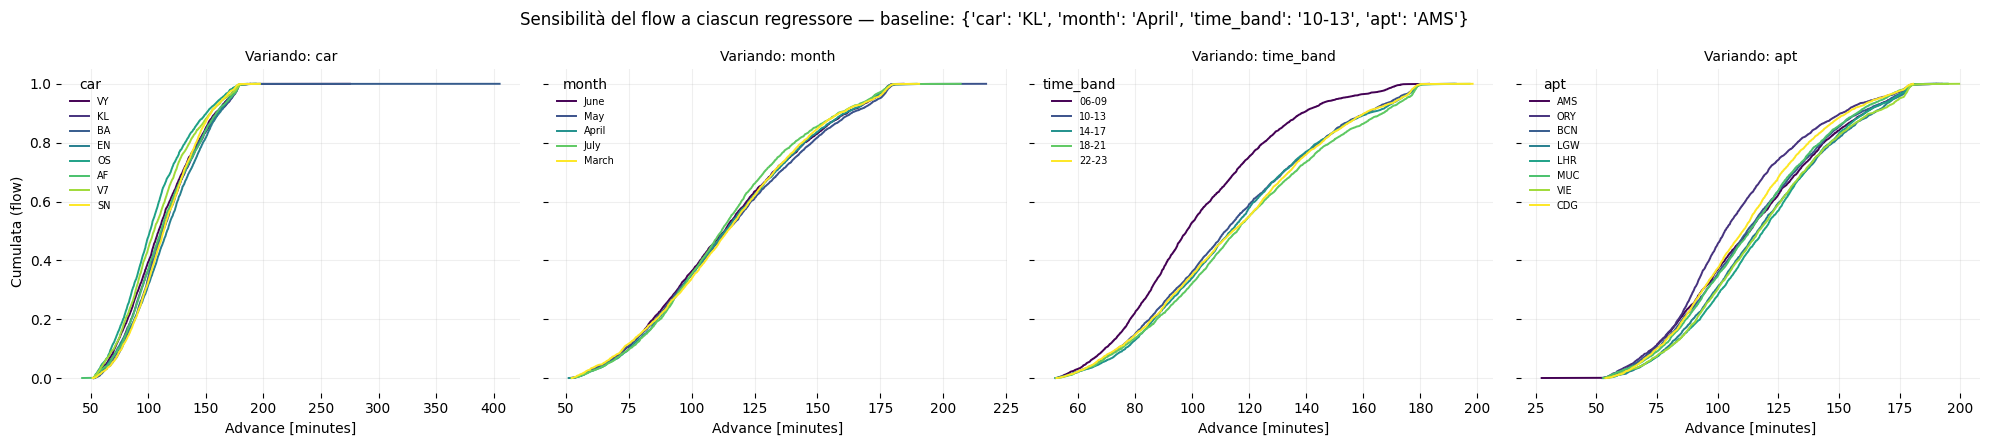

In [51]:
TIME_BAND_ORDER = ["00-05", "06-09", "10-13", "14-17", "18-21", "22-23"]
BASE_COMBO = dict(zip(
    cat_cols,
    train_df.groupby(cat_cols)["flight_key"].nunique().idxmax()
))

TOP_N = 8  # valori più frequenti da confrontare per categoria, altrimenti apt/car sono illeggibili

fig, axes = plt.subplots(1, len(cat_cols), figsize=(5 * len(cat_cols), 4.5), sharey=True)

for ax, cat in zip(axes, cat_cols):
    if cat == "time_band":
        top_values = [v for v in TIME_BAND_ORDER if v in train_df["time_band"].unique()]
    else:
        top_values = (
            train_df.groupby(cat)["flight_key"].nunique()
            .sort_values(ascending=False)
            .head(TOP_N)
            .index
        )

    colors = plt.cm.viridis(np.linspace(0, 1, len(top_values)))

    for value, color in zip(top_values, colors):
        combo = {**BASE_COMBO, cat: value}
        sampled = sample_advance(combo["car"], combo["month"], combo["time_band"], combo["apt"], n_samples=3000)
        s = np.sort(sampled)
        ax.plot(s, np.arange(1, len(s) + 1) / len(s), color=color, linewidth=1.4, label=str(value))

    ax.set_title(f"Variando: {cat}", fontsize=10)
    ax.set_xlabel("Advance [minutes]")
    ax.grid(alpha=0.2)
    ax.legend(frameon=False, fontsize=7, title=cat)
    for spine in ax.spines.values():
        spine.set_visible(False)

axes[0].set_ylabel("Cumulata (flow)")
fig.suptitle(f"Sensibilità del flow a ciascun regressore — baseline: {BASE_COMBO}")
plt.tight_layout()

#### save for production

In [52]:
torch.save({
    "embedder_state": embedder.state_dict(),
    "flow_state": flow.state_dict(),
    "code_lookup": code_lookup,
    "cardinalities": cardinalities,
    "cat_cols": cat_cols,
    "log_adv_mean": log_adv_mean,
    "log_adv_std": log_adv_std,
    "embed_dim": embed_dim,
    "transforms": 3,
    "hidden_features": (64, 64),
}, f"data/arrival_flow.pt")

### Allocation

#### single funcs

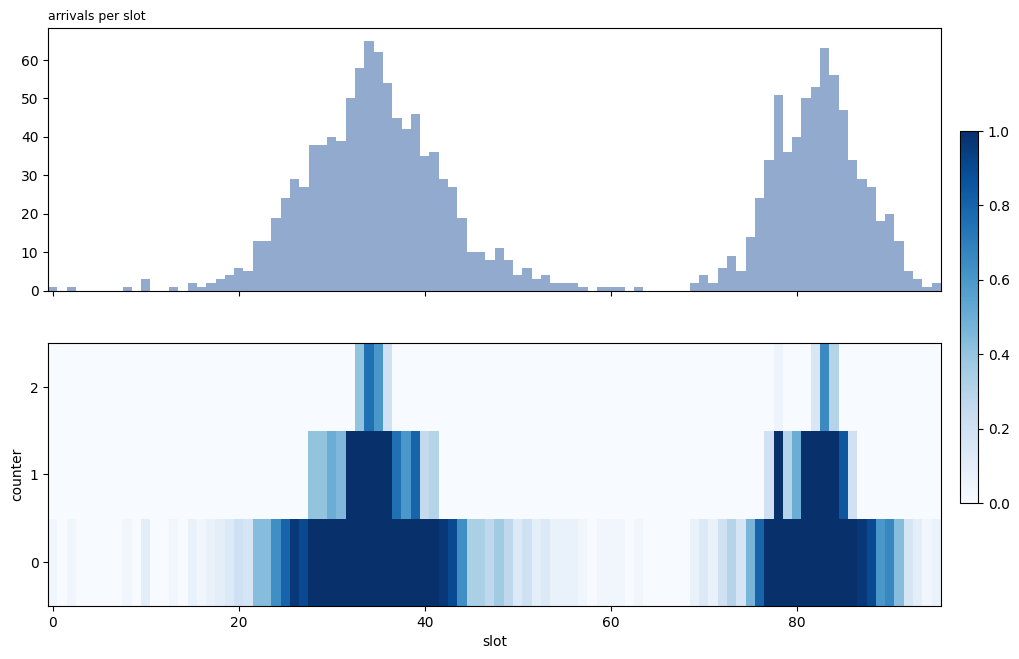

In [36]:
def _synthetic_day(seed, T=96):
    rng = np.random.default_rng(seed)
    t = np.arange(T)
    lam = np.full(T, 0.5)                           # baseline: pax / 15 min
    for _ in range(rng.integers(1, 7)):             # 1-2 peaks
        center, width, height = rng.uniform(10, T - 10), rng.uniform(4, 9), rng.uniform(6, 60)
        lam += height * np.exp(-0.5 * ((t - center) / width) ** 2)
    return rng.poisson(lam).astype(int).tolist()

from app.services.security_class import arrivals_to_demand_grid, arrivals_to_demand_grid_het

def plot_grid(arrivals, D):
    T = D.shape[1]
    x = np.arange(T)
    fig, axes = plt.subplots(2, 1, figsize=(12, 7.5), sharex=True,
                             gridspec_kw={"height_ratios": [1, 1]})
    axes[0].bar(x, arrivals, width=1.0, color="#4C72B0", alpha=0.6)
    axes[0].set_title("arrivals per slot", fontsize=9, loc="left")
    im = axes[1].imshow(D, aspect="auto", origin="lower", cmap="Blues", vmin=0, vmax=1,
                        extent=[-0.5, T - 0.5, -0.5, D.shape[0] - 0.5], interpolation="nearest")
    axes[1].set_yticks(range(D.shape[0]))
    axes[1].set_ylabel("counter")
    axes[1].set_xlabel("slot")
    fig.colorbar(im, ax=axes, fraction=0.02, pad=0.02)
    plt.show()

arrivals = _synthetic_day(seed=1)

registry={
    1: {'label': '1', 'processing_rate': 20, 'processing_unit': 15, 'priority': 5},
    2: {'label': '2', 'processing_rate': 20, 'processing_unit': 15, 'priority': 5},
    3: {'label': '3', 'processing_rate': 30, 'processing_unit': 15, 'priority': 1},
    4: {'label': '4', 'processing_rate': 20, 'processing_unit': 15, 'priority': 5},
    5: {'label': '5', 'processing_rate': 20, 'processing_unit': 15, 'priority': 5},
    6: {'label': '6', 'processing_rate': 20, 'processing_unit': 15, 'priority': 5},
    }
server_registry = preprocessing.build_processing_params_by_server(registry)
server_labels = utils.sort_labels_by_priority(server_registry)
rate_by_label, _ = utils.get_processing_rate_by_label(server_registry, 15)

rates_in_order = [rate_by_label[l] for l in server_labels]

grid = arrivals_to_demand_grid_het(arrivals, rates_in_order)
plot_grid(arrivals, grid)

In [37]:
from app.services.coverage_dp import coverage_report, solve_coverage_batch, allocate_budget, solve_allocated

L_cells, theta = 12, 0.1
curve = solve_coverage_batch(grid, L_cells, theta)

K_total = 20
g = allocate_budget(curve, K_total, exact=True)

sols = solve_allocated(grid, L_cells, theta, g)

print(f"{'ctr':>3} {'k':>3} {'value':>8} | {'inside':>7} {'outside':>8} {'missed':>7}")
for i, s in enumerate(sols):
    print(f"{i:>3} {g.k[i]:>3} {s.value:>8.2f} | {s.inside:>7.2f} {s.outside:>8.2f} {s.missed:>7.2f}")

ctr   k    value |  inside  outside  missed
  0   8    33.37 |   39.37    20.63    0.93
  1   8    13.55 |   15.95     8.05    0.55
  2   4     0.75 |    1.95    10.05    1.15


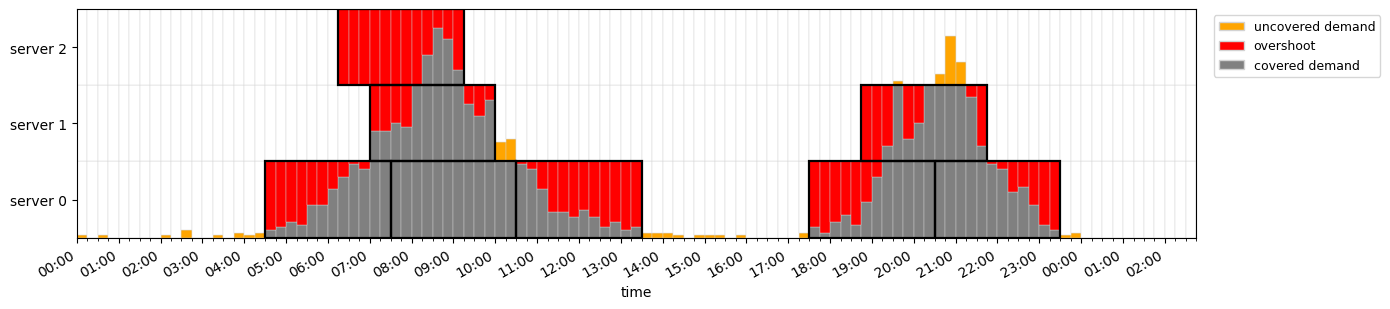

In [38]:
def plot_grid_overlay(grid, alloc, time_values, L=None):

    import matplotlib.dates as mdates
    from matplotlib.patches import Patch, Rectangle

    D = np.asarray(grid, dtype=np.float64)
    if isinstance(alloc, (list, tuple)):                     # list of Solution
        cov = np.vstack([np.asarray(s.coverage, dtype=bool) for s in alloc])
    else:                                                    # bool matrix (n_rows, T)
        cov = np.asarray(alloc, dtype=bool)
    if cov.shape[0] != D.shape[0] or cov.shape[1] < D.shape[1]:
        raise ValueError(f"alloc shape {cov.shape} incompatible with grid shape {D.shape}")
    real_bins = D.shape[1]
    extra = cov.shape[1] - real_bins                         # overhang slots after the end of the day
    if extra:
        D = np.pad(D, ((0, 0), (0, extra)))

    time_values = pd.to_datetime(pd.Series(time_values).reset_index(drop=True))
    n_rows, n_bins = D.shape

    bin_minutes = (
        (time_values.iloc[1] - time_values.iloc[0]).total_seconds() / 60
        if len(time_values) > 1 else 15
    )

    if extra and len(time_values) == real_bins:              # extend the time axis over the overhang
        more = time_values.iloc[-1] + pd.to_timedelta(np.arange(1, extra + 1) * bin_minutes, unit="min")
        time_values = pd.concat([time_values, pd.Series(more)], ignore_index=True)
    if len(time_values) != n_bins:
        raise ValueError(f"time_values has {len(time_values)} entries, grid has {n_bins} columns")

    time_values = pd.to_datetime(pd.Series(time_values).reset_index(drop=True))
    n_rows, n_bins = D.shape
    if len(time_values) != n_bins:
        raise ValueError(f"time_values has {len(time_values)} entries, grid has {n_bins} columns")

    x0 = mdates.date2num(time_values)                        # left edge of each bin
    width = bin_minutes / (24 * 60)                          # bin width in matplotlib date units
    GREY, ORANGE, RED, WHITE = "grey", "orange", "red", "white"
    edge = dict(edgecolor="lightgray", linewidth=0.3)

    fig, ax = plt.subplots(figsize=(14, 0.4 * n_rows + 2))
    for c in range(n_rows):
        d, covered = D[c], cov[c]
        # bottom part: demand  (grey if covered, orange if not)
        m = d > 1e-9
        ax.bar(x0[m], d[m], width=width, bottom=c, align="edge",
               color=np.where(covered[m], GREY, ORANGE), **edge)
        # top part: capacity not needed  (red if covered = waste, white if not)
        idle = 1.0 - d
        m = idle > 1e-9
        ax.bar(x0[m], idle[m], width=width, bottom=c + d[m], align="edge",
               color=np.where(covered[m], RED, WHITE), **edge)

    # outlined rectangle per shift block
    if isinstance(alloc, (list, tuple)) and L is not None:
        blocks = [(c, int(s0), int(L)) for c, sol in enumerate(alloc) for s0 in sol.starts]

    for c, s0, ln in blocks:
        ax.add_patch(Rectangle((x0[s0], c), ln * width, 1, fill=False,
                               edgecolor="black", linewidth=1.6, zorder=3))
        
    ax.set_xlim(x0[0], x0[-1] + width)
    ax.set_ylim(0, n_rows)
    ax.set_yticks(np.arange(n_rows) + 0.5)
    ax.set_yticklabels([f"server {y}" for y in range(n_rows)])

    ax.xaxis_date()
    ax.xaxis.set_major_locator(mdates.HourLocator(interval=1))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    ax.xaxis.set_minor_locator(mdates.MinuteLocator(byminute=[0, 15, 30, 45]))
    ax.set_xlabel("time")

    legend_handles = [
        Patch(facecolor=ORANGE, edgecolor="lightgray", label="uncovered demand"),
        Patch(facecolor=RED, edgecolor="lightgray", label="overshoot"),
        Patch(facecolor=GREY, edgecolor="lightgray", label="covered demand"),
    ]
    ax.legend(handles=legend_handles, loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)
    fig.autofmt_xdate()
    fig.tight_layout()
    plt.show()

time_values = pd.date_range("2026-01-01 00:00", periods=grid.shape[1], freq=f"15min")
plot_grid_overlay(grid, sols, time_values, L=L_cells)

In [39]:
rep = coverage_report(grid, sols, L_cells, time_values, theta=theta)

rep.total

n_blocks           8.000000
demand            59.900000
covered_demand    57.266667
missed_demand      2.633333
idle_capacity     38.733333
coverage           0.956038
objective         47.666667
dtype: float64

In [7]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.dates as mdates
from matplotlib.patches import Rectangle, Patch

def plot_allocation_multi(grid, sols, time_values, alpha, row_labels=None):
    """
    grid        : (n_rows, T) demand grid in [0, 1]
    sols        : list of MultiSolution, one per row that has a server (fewer than n_rows is fine)
    time_values : (T,) bin start times (regular step)
    alpha       : alpha used by the solver (for the objective in the title)
    row_labels  : names of the rows with a server (default 1..len(sols)); the other rows are "no server"
    """
    D = np.asarray(grid, dtype=np.float64)
    n_rows, T = D.shape
    if len(sols) > n_rows:
        raise ValueError(f"{len(sols)} solutions for {n_rows} rows")

    # bins after the end of the day (overhang): same length as the solutions' coverage
    T_ext = max([T] + [len(s.coverage) for s in sols])
    tv = pd.to_datetime(pd.Series(time_values).reset_index(drop=True))
    step = tv.iloc[1] - tv.iloc[0]
    tv_ext = pd.DatetimeIndex(tv.iloc[0] + step * np.arange(T_ext))
    D = np.pad(D, ((0, 0), (0, T_ext - T)))
    cov = np.zeros(D.shape, dtype=bool)
    blocks = []                                           # (row, start_dt, end_dt)
    for c, sol in enumerate(sols):
        cov[c, :len(sol.coverage)] = sol.coverage
        for s, l in zip(sol.starts, sol.lengths):
            blocks.append((c, tv_ext[int(s)], tv_ext[int(s)] + int(l) * step))

    total = float(D.sum())
    C = float(D[cov].sum())
    I = float((1.0 - D)[cov].sum())
    obj, coverage = C - alpha * I, (C / total if total > 0 else 1.0)

    labels = list(row_labels) if row_labels is not None else list(range(1, len(sols) + 1))
    x0 = mdates.date2num(tv_ext)                          # left edge of each bin
    width = step.total_seconds() / 86400                  # bin width in matplotlib date units
    GREY, ORANGE, RED, WHITE = "grey", "orange", "red", "white"
    edge = dict(edgecolor="lightgray", linewidth=0.3)

    fig, ax = plt.subplots(figsize=(10, 0.4 * n_rows + 1))
    for c in range(n_rows):
        d, covered = D[c], cov[c]
        m = d > 1e-9
        ax.bar(x0[m], d[m], width=width, bottom=c, align="edge",
               color=np.where(covered[m], GREY, ORANGE), **edge)
        idle = 1.0 - d
        m = idle > 1e-9
        ax.bar(x0[m], idle[m], width=width, bottom=c + d[m], align="edge",
               color=np.where(covered[m], RED, WHITE), **edge)

    multi_length = len({int(l) for s in sols for l in s.lengths}) > 1
    for c, start, end in blocks:
        xs, xe = mdates.date2num(start), mdates.date2num(end)
        ax.add_patch(Rectangle((xs, c), xe - xs, 1, fill=False, edgecolor="black", linewidth=1.6, zorder=3))
        if multi_length:                                  # durata scritta dentro il blocco
            h = (end - start).total_seconds() / 3600
            ax.text((xs + xe) / 2, c + 0.5, f"{h:g}h", ha="center", va="center", fontsize=7, zorder=4)

    ax.set_ylim(0, n_rows)
    ax.set_yticks(np.arange(n_rows) + 0.5)
    ax.set_yticklabels([f"server {labels[c]}" if c < len(sols) else "no server" for c in range(n_rows)])
    ax.legend(handles=[Patch(facecolor=ORANGE, edgecolor="lightgray", label="uncovered"),
                       Patch(facecolor=RED, edgecolor="lightgray", label="overshoot"),
                       Patch(facecolor=GREY, edgecolor="lightgray", label="covered")],
              loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)

    ax.set_xlim(x0[0], x0[-1] + width)
    ax.xaxis_date()
    ax.xaxis.set_major_locator(mdates.HourLocator(interval=2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    ax.xaxis.set_minor_locator(mdates.MinuteLocator(byminute=[0, 15, 30, 45]))
    ax.set_axisbelow(True)
    ax.grid(axis="x", which="major", linestyle="-", alpha=0.5, zorder=1)

    hours = pd.Series([(e - s).total_seconds() / 3600 for _, s, e in blocks]).round(2)
    shifts = " + ".join(f"{n}×{h:g}h" for h, n in hours.value_counts().sort_index().items()) or "no shifts"
    fig.suptitle(f"shifts: {shifts}  |  alpha = {alpha:g}  |  {len(blocks)} blocks  |  "
                 f"obj = {obj:.2f}  |  coverage = {coverage:.1%}")
    fig.autofmt_xdate(rotation=90)
    fig.tight_layout()
    plt.show()

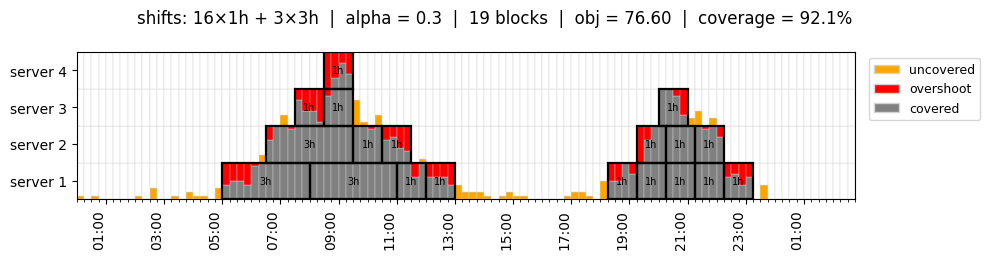

In [8]:
from app.services.coverage_dp import coverage_report_multi, solve_coverage_batch_multi, allocate_budget_multi, solve_allocated_multi, allocate_milp

lengths=[12, 4]
theta=0.3
K_total= 20
length_totals={12:3}

curves = solve_coverage_batch_multi(grid, lengths, theta)
alloc = allocate_budget_multi(curves, lengths, K_total=K_total, length_totals=length_totals)
sols = solve_allocated_multi(grid, theta, alloc)

time_values = pd.date_range("2026-06-01 00:00", periods=grid.shape[1], freq="15min")

report = coverage_report_multi(grid, sols, time_values=time_values, theta=theta)

plot_allocation_multi(grid, sols, time_values, theta)

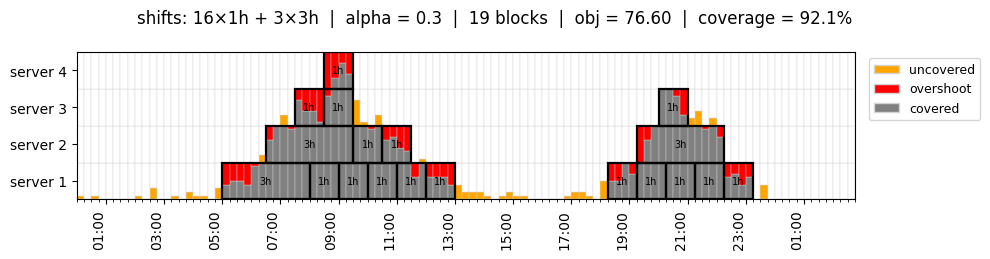

In [9]:
alloc = allocate_milp(curves, lengths, K_total=K_total, length_per_day=length_totals)
sols = solve_allocated_multi(grid, theta, alloc)

time_values = pd.date_range("2026-06-01 00:00", periods=grid.shape[1], freq="15min")

report = coverage_report_multi(grid, sols, time_values=time_values, theta=theta)

plot_allocation_multi(grid, sols, time_values, theta)

#### class and synthetic arrivals

In [2]:
def make_synthetic_arrivals(
    pax_per_server_bin: float,
    peak_servers=(4.2, 3.4),
    peak_hours=(8.0, 17.5),
    widths_h=(1.6, 2.0),
    base_servers=0.15,
    day="2026-03-02",
    bin_minutes=15,
    seed=0,
) -> pd.Series:
    T = 24 * 60 // bin_minutes
    t_h = (np.arange(T) + 0.5) * bin_minutes / 60                      # centro del bin, in ore
    servers_needed = np.full(T, base_servers)
    for hour, width, amp in zip(peak_hours, widths_h, peak_servers):
        servers_needed += amp * np.exp(-0.5 * ((t_h - hour) / width) ** 2)
    rng = np.random.default_rng(seed)
    index = pd.date_range(day, periods=T, freq=f"{bin_minutes}min")
    return pd.Series(rng.poisson(servers_needed * pax_per_server_bin).astype(float),
                     index=index, name="arrivals")

BIN_MINUTES = 15
arrivals = make_synthetic_arrivals(30, seed=1)

registry={
    1: {'label': '1', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    2: {'label': '2', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    3: {'label': '3', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    4: {'label': '4', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    5: {'label': '5', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    6: {'label': '6', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    7: {'label': '7', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    8: {'label': '8', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    }
server_registry = preprocessing.build_processing_params_by_server(registry)

2026-10-28 12:03:23,416 | INFO | app.services.security_class | [SecurityPlanner] Launching allocation DP: L=1.00h, theta=0.50


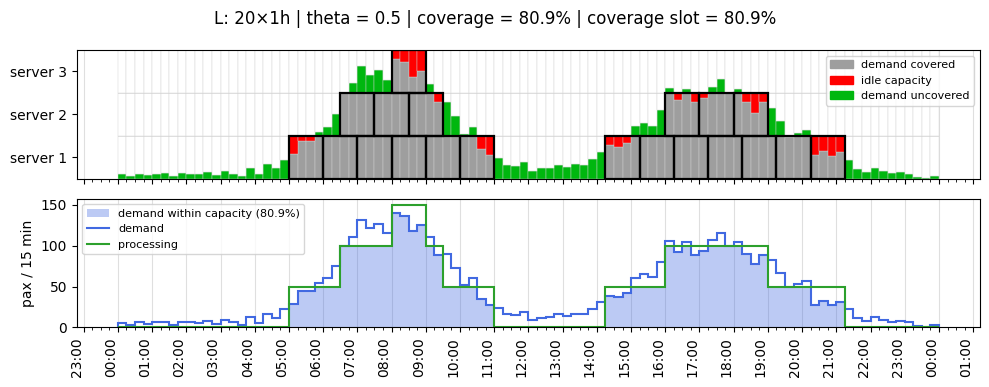

In [3]:
planner = security_class.SecurityPlanner(arrivals, server_registry)

res = planner.run(L=1, theta=0.5, K_total=1000)

plotutils.plot_allocation(res)

2026-10-28 12:03:24,435 | INFO | app.services.security_class | [SecurityPlanner] Launching multi-length allocation: lengths=[1.0, 3.0] h, theta=0.80


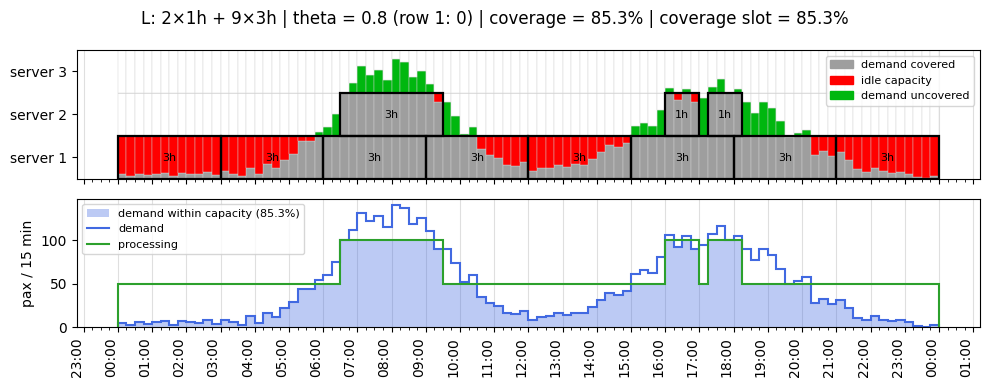

In [4]:
res = planner.run_multi(lengths=[1, 3], theta=0.8, K_total=1000, theta_first=0)

plotutils.plot_allocation(res)

#### from schedule (single day)

In [3]:
date=dt.datetime(2026, 6, 1)

schedule_or= pd.read_excel(os.path.join('data', 'schedule.xlsx'))
schedule_std= preprocessing.preprocess_schedule_FLR(schedule_or, profile_specs={})
schedule_f = schedule_std[schedule_std["date"] == date].copy()

schedule_pred = predictive.predict_pax(df=schedule_f, path=f"data/pax_model.joblib")
arrival_model = arrival_flow.load_arrival_flow(os.path.join("data", "arrival_flow.pt"))

flight_demand = preprocessing.build_flight_demand(schedule_pred, arrival_model=arrival_model)

registry={
    1: {'label': '1', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    2: {'label': '2', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    3: {'label': '3', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    4: {'label': '4', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    5: {'label': '5', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    6: {'label': '6', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    }
server_registry = preprocessing.build_processing_params_by_server(registry)

2026-10-28 12:08:11,808 | WARNING | app.services.preprocessing | More than 10% of flights (12/62) fall back to the unknown arrival sampler. Check the arrival model coverage.


2026-10-28 12:08:33,048 | INFO | app.services.security_class | [SecurityPlanner] Launching multi-length allocation: lengths=[2.0] h, theta=0.40


2026-10-28 12:08:33,816 | INFO | app.services.security_class | [SecuritySimulator] Launching pool: 30 total tasks, 4 workers


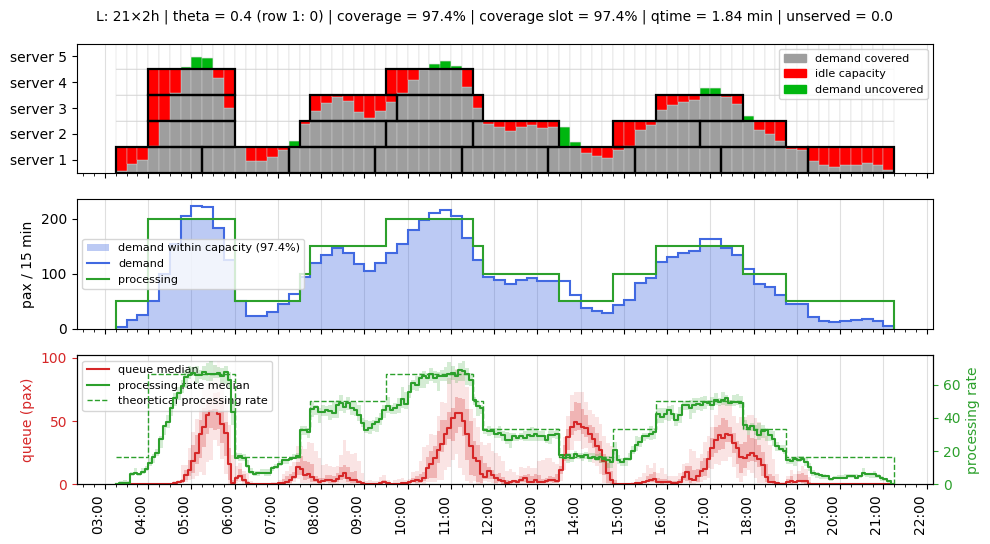

In [5]:
arrivals= security_class.expected_arrivals(flight_demand)
planner = security_class.SecurityPlanner(arrivals, server_registry)

lengths=[2]
length_totals={}
K_total=1000

res = planner.run_multi(lengths=lengths, length_totals=length_totals, theta=0.4, K_total=K_total, theta_first=0)

classe2= security_class.SecuritySimulator(
    flight_demand=flight_demand,
    intervals=utils.server_schedule_to_intervals(res.server_schedule),
    server_registry=server_registry)
sim_results = classe2.run(n_scenarios=30, n_workers=4, timebin=5, base_seed=base_seed)

plotutils.plot_allocation(res, df_timeline=sim_results.df_timeline, df_kpis=sim_results.df_kpis)

#### from schedule (multiple day)

In [2]:
dates = pd.date_range("2026-06-01", periods=5, freq="D")

schedule_or= pd.read_excel(os.path.join('data', 'schedule.xlsx'))
schedule_std= preprocessing.preprocess_schedule_FLR(schedule_or, profile_specs={})
schedule_f = schedule_std[schedule_std["date"].isin(dates)].copy()

schedule_pred = predictive.predict_pax(df=schedule_f, path=f"data/pax_model.joblib")
arrival_model = arrival_flow.load_arrival_flow(os.path.join("data", "arrival_flow.pt"))

flight_demand = preprocessing.build_flight_demand(schedule_pred, arrival_model=arrival_model)
arrivals= security_class.expected_arrivals(flight_demand)

registry={
    1: {'label': '1', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    2: {'label': '2', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    3: {'label': '3', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    4: {'label': '4', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    5: {'label': '5', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    6: {'label': '6', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    }
server_registry = preprocessing.build_processing_params_by_server(registry)

2026-10-28 12:08:01,091 | WARNING | app.services.preprocessing | More than 10% of flights (54/306) fall back to the unknown arrival sampler. Check the arrival model coverage.


In [ ]:
lengths=[4, 1.5]
theta=0.7
K_total=1000
length_per_day={4:10, 1.5:15}

planner = security_class.MultiDayPlanner(arrivals, server_registry)

res = planner.run(lengths=lengths, theta=0.5, K_total=K_total, length_per_day=length_per_day)

2026-10-19 16:10:37,093 | INFO | app.services.security_class | [MultiDayPlanner] curves: 5 days x 5 layers, lengths=[1.5, 4.0] h, alpha=0.50


In [4]:
planner.report_by_day()

,n_blocks,demand,covered_demand,missed_demand,idle_capacity,coverage,objective,n_blocks_6,n_blocks_16
day,,,,,,,,,
2026-06-01,16,138.16,129.714531,8.445469,16.285469,0.938872,121.571797,11,5
2026-06-02,17,129.90,122.866786,7.033214,19.133214,0.945857,113.300179,13,4
2026-06-03,16,117.02,109.130430,7.889570,16.869570,0.932579,100.695645,13,3
2026-06-04,16,128.78,119.050174,9.729826,16.949826,0.924446,110.575261,12,4
2026-06-05,18,142.04,134.869670,7.170330,23.130330,0.949519,123.304505,13,5


In [ ]:
for n, r in enumerate(res.day_results):
    print(planner.days[n].date())
    plotutils.plot_allocation(r, show_second=False)

#### Random movements (single day)

In [2]:
from app.services.perturbation import *
import app.services.simulation_batch as sb  
import app.services.local_search as ls

date=dt.datetime(2026, 6, 1)

In [8]:
theta = 0.4
lengths=[2]
length_totals={2:100}
K_total=1000

schedule_or= pd.read_excel(os.path.join('data', 'schedule.xlsx'))
schedule_std= preprocessing.preprocess_schedule_FLR(schedule_or, profile_specs={})
schedule_f = schedule_std[schedule_std["date"] == date].copy()

schedule_pred = predictive.predict_pax(df=schedule_f, path=f"data/pax_model.joblib")
arrival_model = arrival_flow.load_arrival_flow(os.path.join("data", "arrival_flow.pt"))

flight_demand = preprocessing.build_flight_demand(schedule_pred, arrival_model=arrival_model)

registry={
    1: {'label': '1', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    2: {'label': '2', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    3: {'label': '3', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    4: {'label': '4', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    5: {'label': '5', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    6: {'label': '6', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    }
server_registry = preprocessing.build_processing_params_by_server(registry)
arrivals= security_class.expected_arrivals(flight_demand)
planner = security_class.SecurityPlanner(arrivals, server_registry)

plotutils.save_context(planner, os.path.join("data", f"context_{date.date()}.npz"))

2026-10-28 12:39:05,728 | WARNING | app.services.preprocessing | More than 10% of flights (12/62) fall back to the unknown arrival sampler. Check the arrival model coverage.


In [ ]:
res = planner.run_multi(lengths=lengths, length_totals=length_totals, theta=theta, K_total=K_total, theta_first=0)
plotutils.plot_allocation(res, show_second=False)

2026-10-28 12:39:08,969 | INFO | app.services.security_class | [SecurityPlanner] Launching multi-length allocation: lengths=[2.0] h, theta=0.00


theta=0.0, batch=0: 100 new schedules


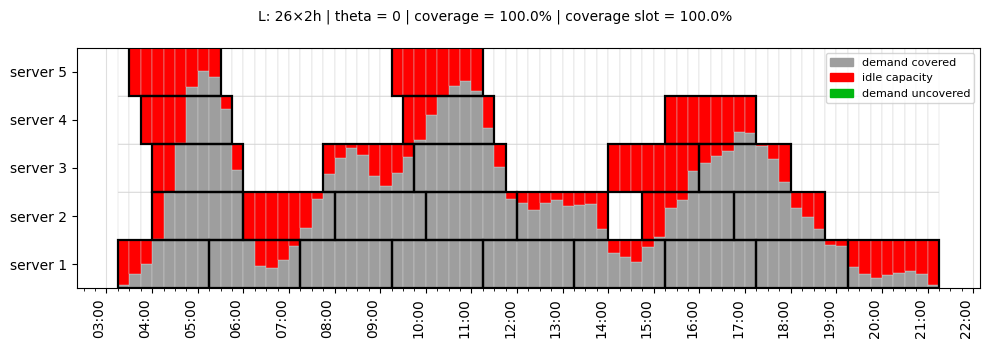

2026-10-28 12:45:34,225 | INFO | app.services.security_class | [SecurityPlanner] Launching multi-length allocation: lengths=[2.0] h, theta=0.10


theta=0.0, batch=0: saved
theta=0.1, batch=0: 100 new schedules


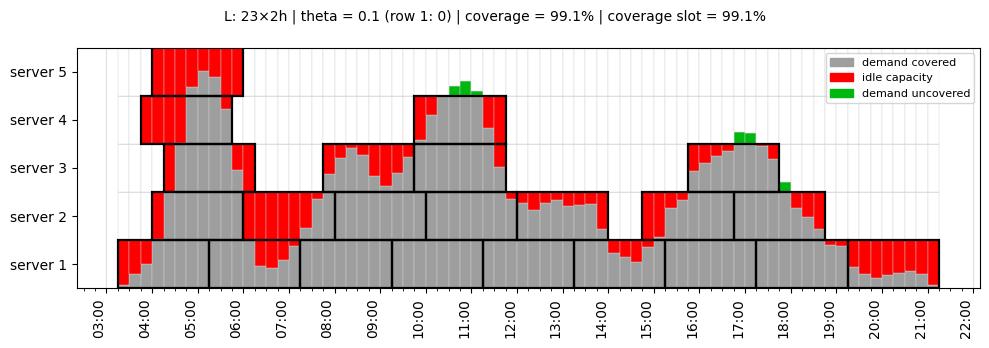

2026-10-28 12:52:48,508 | INFO | app.services.security_class | [SecurityPlanner] Launching multi-length allocation: lengths=[2.0] h, theta=0.20


theta=0.1, batch=0: saved
theta=0.2, batch=0: 100 new schedules


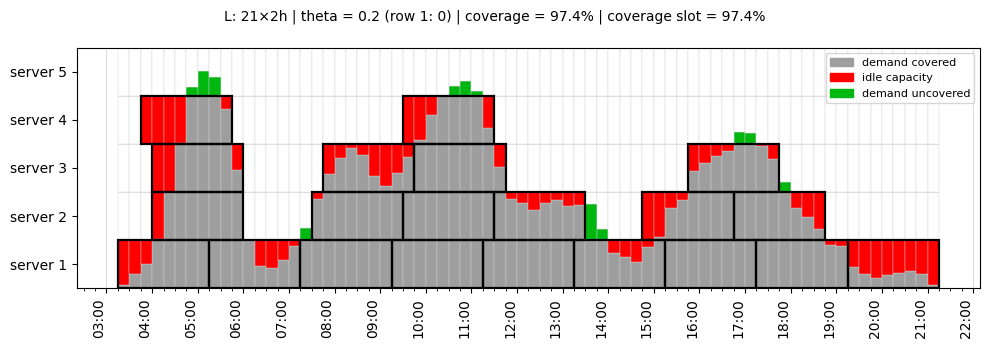

2026-10-28 13:00:56,906 | INFO | app.services.security_class | [SecurityPlanner] Launching multi-length allocation: lengths=[2.0] h, theta=0.30


theta=0.2, batch=0: saved
theta=0.3, batch=0: 100 new schedules


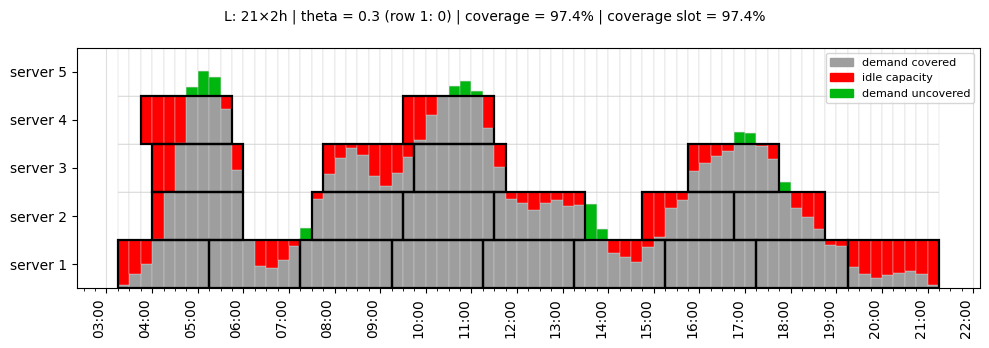

2026-10-28 13:08:39,665 | INFO | app.services.security_class | [SecurityPlanner] Launching multi-length allocation: lengths=[2.0] h, theta=0.40


theta=0.3, batch=0: saved
theta=0.4, batch=0: 100 new schedules


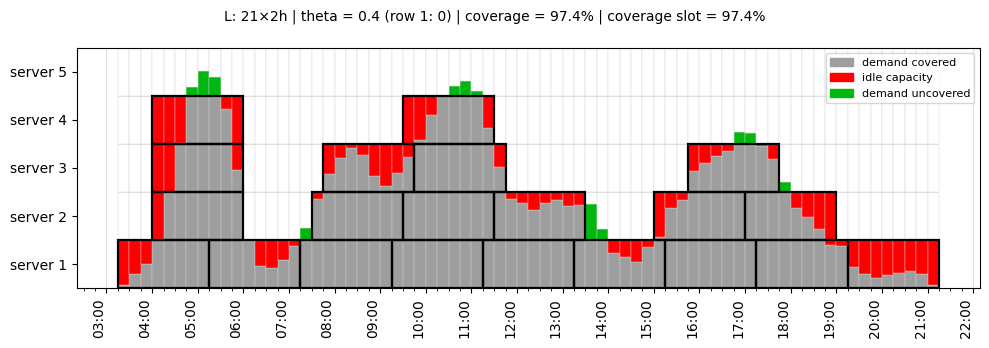

2026-10-28 13:16:18,370 | INFO | app.services.security_class | [SecurityPlanner] Launching multi-length allocation: lengths=[2.0] h, theta=0.50


theta=0.4, batch=0: saved
theta=0.5, batch=0: 100 new schedules


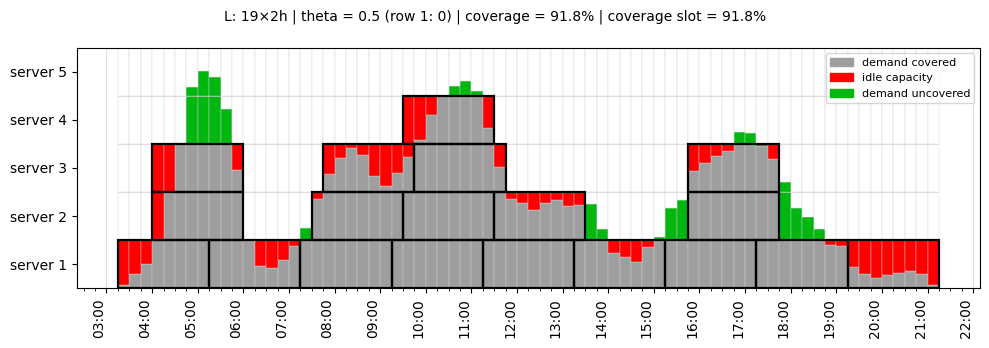

2026-10-28 13:24:38,708 | INFO | app.services.security_class | [SecurityPlanner] Launching multi-length allocation: lengths=[2.0] h, theta=0.60


theta=0.5, batch=0: saved
theta=0.6, batch=0: 100 new schedules


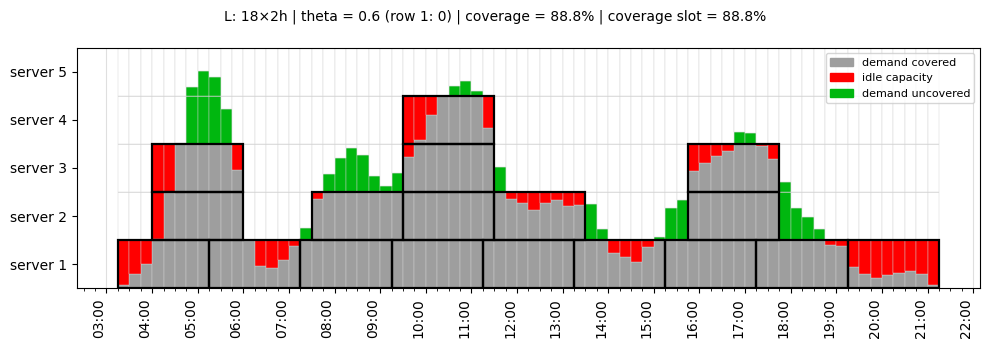

2026-10-28 13:35:09,912 | INFO | app.services.security_class | [SecurityPlanner] Launching multi-length allocation: lengths=[2.0] h, theta=0.70


theta=0.6, batch=0: saved
theta=0.7, batch=0: 100 new schedules


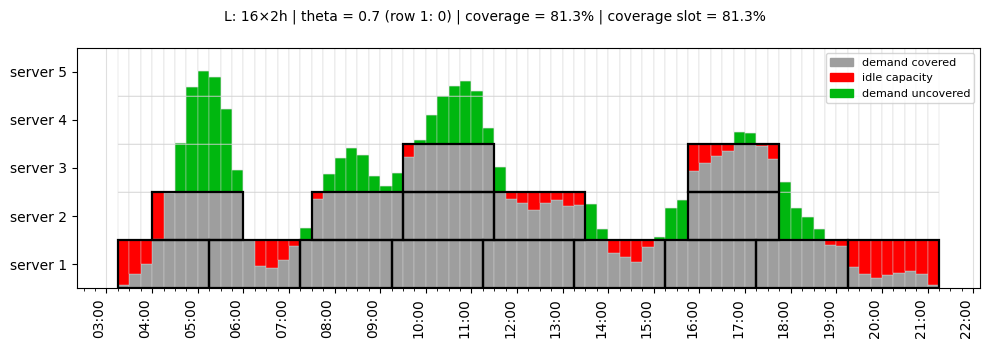

2026-10-28 13:58:38,769 | INFO | app.services.security_class | [SecurityPlanner] Launching multi-length allocation: lengths=[2.0] h, theta=0.80


theta=0.7, batch=0: saved
theta=0.8, batch=0: 100 new schedules


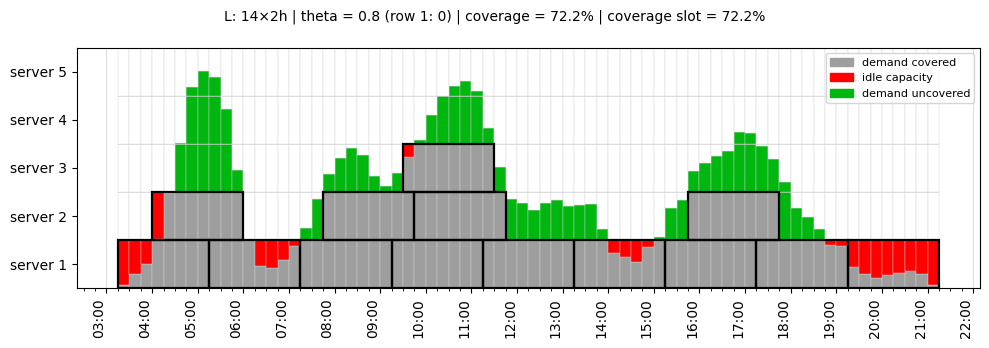

In [ ]:
theta_step = 0.1
theta_first = 0
max_moves = 5
n_reps = 99
step=3
batch_id = 0

T = planner.demand_grid.shape[1]
out_path = os.path.join("data", f"perturbation_study_{date.date()}.xlsx")

PENALTIES = [60, 120]
N_pax = float(planner.arrivals.sum())
arr_np = planner.arrivals.to_numpy()

df_prev = pd.read_excel(out_path) if os.path.exists(out_path) else pd.DataFrame()
if len(df_prev) and "batch" not in df_prev:
    df_prev["batch"] = 0
rows = df_prev.to_dict("records")
done = {(round(a, 6), int(b)) for a, b in zip(df_prev["theta"], df_prev["batch"])} if len(df_prev) else set()
rep = int(df_prev["rep"].max()) + 1 if len(df_prev) else 0

for theta_i in np.arange(0.0, 1, theta_step):
    theta_i = round(float(theta_i), 6)
    if (round(theta_i, 6), batch_id) in done:
        print(f"theta={theta_i}, batch={batch_id}: already in {out_path}, skipped")
        continue
    res_a = planner.run_multi(lengths=lengths, length_totals=length_totals, theta=theta_i, K_total=K_total, theta_first=theta_first)
    base = schedule_to_blocks(planner, res_a)
    n_blocks = sum(len(v) for v in base.values())
    if n_blocks == 0:
        print(f"theta={theta_i}: no windows opened, skipped")
        continue

    rng = np.random.default_rng([42, int(round(theta_i * 1000)), batch_id])

    # schedule gia' presenti per questo alpha: non vanno ripetute
    mine = [r for r in rows if np.isclose(r["theta"], theta_i)]
    seen = {r["blocks"] for r in mine} | {blocks_to_json(base)}
    offset = len(mine)                                      

    # 1) schedule del lotto (la baseline solo nel lotto 0)
    schedules = [(base, [])] if batch_id == 0 else []
    target = n_reps + (1 if batch_id == 0 else 0)
    for _ in range(20 * n_reps):
        if len(schedules) >= target:
            break
        k = int(rng.integers(1, max_moves + 1))
        blocks, moves = perturb_blocks(base, T, k, rng, step=step)
        key = blocks_to_json(blocks)
        if key in seen:
            continue
        seen.add(key)
        schedules.append((blocks, moves))
    print(f"theta={theta_i}, batch={batch_id}: {len(schedules)} new schedules")
    if not schedules:
        continue

    if batch_id == 0:
        plotutils.plot_allocation(res_with_blocks(planner, res_a, base), show_second=False)

    # 2) simulazioni
    intervals_list = [utils.server_schedule_to_intervals(blocks_to_schedule(planner, b)) for b, _ in schedules]
    batch = 100
    parts, tl_parts = [], []
    for i0 in range(0, len(intervals_list), batch):
        k_part, t_part = sb.simulate_kpis(flight_demand, intervals_list[i0:i0 + batch], server_registry,
                                       n_scenarios=50, n_workers=os.cpu_count(), timebin=15,
                                       base_seed=base_seed, return_timeline=True)
        parts.append(k_part); tl_parts += t_part
    kpis = pd.concat(parts, ignore_index=True)

    # 3) coda fluida, J, righe
    for j, (blocks, moves) in enumerate(schedules):
        rep_theta = offset + j
        k = kpis.iloc[j]
        q_f, u_f = ls.fluid_metrics(arr_np, planner.rate_by_label, blocks, planner.bin_minutes)
        q_s, u_s = float(k["qtime_mean"]), float(k["n_unserved"])
        J = {}
        for P in PENALTIES:
            J[f"J_fluid_P{P}"] = ((N_pax - u_f) * q_f + P * u_f) / N_pax
            J[f"J_sim_P{P}"]   = ((N_pax - u_s) * q_s + P * u_s) / N_pax
        rows.append(dict(
            date=date, lengths=str(lengths), length_totals=str(length_totals), K_total=K_total,
            theta=theta_i, theta_first=theta_first, batch=batch_id, n_blocks=n_blocks, rep=rep, rep_theta=rep_theta,
            is_baseline=(batch_id == 0 and j == 0), n_pax=N_pax,
            **coverage_from_blocks(planner, res_a, blocks),
            coverage_slot=coverage_slotwise(arr_np, planner.rate_by_label, blocks),
            q_fluid=q_f, unserved_fluid=u_f, **J,
            qtime_mean=q_s, n_unserved=u_s, qtime_above_30_pct=k["qtime_above_30_pct"],
            n_moves=len(moves), moves=json.dumps(moves), blocks=blocks_to_json(blocks),
            timeline=json.dumps(tl_parts[j])))
        rep += 1

    pd.DataFrame(rows).to_excel(out_path, index=False)
    print(f"theta={theta_i}, batch={batch_id}: saved")

df_pert = pd.DataFrame(rows)

In [ ]:
date=dt.datetime(2026, 6, 1)
df_pert = pd.read_excel(os.path.join("data", f"perturbation_study_{date.date()}.xlsx"))
df_pert

,date,lengths,length_totals,K_total,theta,theta_first,batch,n_blocks,rep,rep_theta,...,J_sim_P60,J_fluid_P120,J_sim_P120,qtime_mean,n_unserved,qtime_above_30_pct,n_moves,moves,blocks,timeline
0,2026-06-01,[2],{2: 100},1000,0.2,0,0,21,0,0,...,1.948393,0.952311,1.948393,1.948393,0,0.000000,0,[],"{""1"": [[0, 8], [8, 8], [16, 8], [24, 8], [32, ...","{""t0"": ""2026-06-01T03:15:00"", ""step_min"": 15.0..."
1,2026-06-01,[2],{2: 100},1000,0.2,0,0,21,1,1,...,3.132675,2.161659,3.132675,3.132675,0,0.000000,8,"[[""2"", 4, -1], [""3"", 2, 1], [""4"", 0, 3], [""2"",...","{""1"": [[0, 8], [8, 8], [16, 8], [24, 8], [32, ...","{""t0"": ""2026-06-01T03:15:00"", ""step_min"": 15.0..."
2,2026-06-01,[2],{2: 100},1000,0.2,0,0,21,2,2,...,14.089567,13.214176,14.089567,14.089567,0,14.806312,9,"[[""2"", 4, -2], [""2"", 3, 2], [""3"", 3, -3], [""3""...","{""1"": [[0, 8], [8, 8], [16, 8], [24, 8], [32, ...","{""t0"": ""2026-06-01T03:15:00"", ""step_min"": 15.0..."
3,2026-06-01,[2],{2: 100},1000,0.2,0,0,21,3,3,...,4.609433,3.225942,4.609433,4.609433,0,1.705269,4,"[[""2"", 4, -1], [""4"", 0, 1], [""2"", 3, 2], [""3"",...","{""1"": [[0, 8], [8, 8], [16, 8], [24, 8], [32, ...","{""t0"": ""2026-06-01T03:15:00"", ""step_min"": 15.0..."
4,2026-06-01,[2],{2: 100},1000,0.2,0,0,21,4,4,...,9.912286,9.047049,9.912286,9.912286,0,2.326867,10,"[[""3"", 2, 2], [""4"", 1, 2], [""3"", 3, -2], [""2"",...","{""1"": [[0, 8], [8, 8], [16, 8], [24, 8], [32, ...","{""t0"": ""2026-06-01T03:15:00"", ""step_min"": 15.0..."
5,2026-06-01,[2],{2: 100},1000,0.2,0,0,21,5,5,...,2.421106,1.612639,2.421106,2.421106,0,0.000000,4,"[[""2"", 0, 1], [""4"", 0, 1], [""3"", 1, -3], [""2"",...","{""1"": [[0, 8], [8, 8], [16, 8], [24, 8], [32, ...","{""t0"": ""2026-06-01T03:15:00"", ""step_min"": 15.0..."
6,2026-06-01,[2],{2: 100},1000,0.2,0,0,21,6,6,...,5.985928,4.794878,5.985928,5.985928,0,0.221482,4,"[[""3"", 2, 2], [""3"", 1, -1], [""4"", 1, -3], [""2""...","{""1"": [[0, 8], [8, 8], [16, 8], [24, 8], [32, ...","{""t0"": ""2026-06-01T03:15:00"", ""step_min"": 15.0..."
7,2026-06-01,[2],{2: 100},1000,0.2,0,0,21,7,7,...,2.284459,1.160124,2.284459,2.284459,0,0.000000,2,"[[""2"", 4, -2], [""2"", 5, -2]]","{""1"": [[0, 8], [8, 8], [16, 8], [24, 8], [32, ...","{""t0"": ""2026-06-01T03:15:00"", ""step_min"": 15.0..."
8,2026-06-01,[2],{2: 100},1000,0.2,0,0,21,8,8,...,2.037442,1.025251,2.037442,2.037442,0,0.000000,2,"[[""3"", 3, 1], [""3"", 1, -3]]","{""1"": [[0, 8], [8, 8], [16, 8], [24, 8], [32, ...","{""t0"": ""2026-06-01T03:15:00"", ""step_min"": 15.0..."
9,2026-06-01,[2],{2: 100},1000,0.2,0,0,21,9,9,...,3.523895,2.314540,3.523895,3.523895,0,1.705269,1,"[[""4"", 0, -2]]","{""1"": [[0, 8], [8, 8], [16, 8], [24, 8], [32, ...","{""t0"": ""2026-06-01T03:15:00"", ""step_min"": 15.0..."


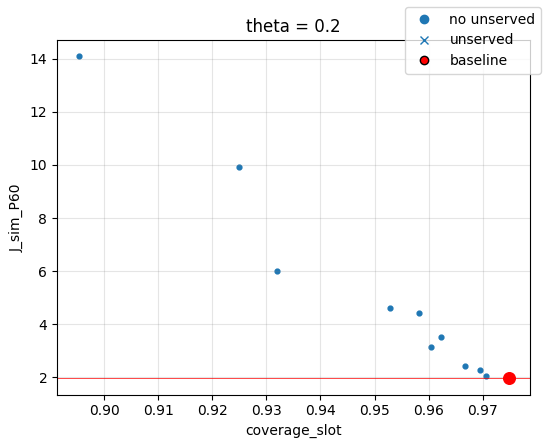

In [ ]:
import math
from matplotlib.lines import Line2D

x, y = "coverage_slot", "J_sim_P60"
u_col, u_tol = "n_unserved", 0.0
max_cols = 4
theta_in = sorted(df_pert["theta"].unique())
theta_in= [x for x in theta_in if x <= 0.7]

n_rows = math.ceil(len(theta_in) / max_cols)
n_cols = min(len(theta_in), max_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(5.5 * n_cols, 4.5 * n_rows), squeeze=False)
flat = axes.ravel()
for ax, a in zip(flat, theta_in):
    d = df_pert[df_pert["theta"] == a]
    d_ok = d[d[u_col] <= u_tol]
    d_un = d[d[u_col] > u_tol]
    ax.scatter(d_ok[x], d_ok[y], s=12, marker="o", color="tab:blue")
    ax.scatter(d_un[x], d_un[y], s=22, marker="x", color="tab:blue", linewidths=1.2)

    if d["is_baseline"].any():
        b = d[d["is_baseline"]].iloc[0]
        has_u = b[u_col] > u_tol
        ax.scatter(b[x], b[y], s=70 if not has_u else 90, marker="x" if has_u else "o",
                   color="red", linewidths=2 if has_u else 1, zorder=3)
        ax.axhline(b[y], color="red", linewidth=0.5)
    ax.set_title(f"theta = {a}")
    ax.set_xlabel(x)
    ax.grid(color="gray", alpha=0.2)

for ax in flat[len(theta_in):]:
    ax.axis("off")
for ax in axes[:, 0]:
    ax.set_ylabel(y)

handles = [Line2D([], [], marker="o", color="tab:blue", linestyle="", label="no unserved"),
           Line2D([], [], marker="x", color="tab:blue", linestyle="", label="unserved"),
           Line2D([], [], marker="o", color="red", markeredgecolor="black", linestyle="", label="baseline")]
fig.legend(handles=handles, loc="upper right")
plt.tight_layout()
plt.show()

In [7]:
df_pert

,date,lengths,length_totals,K_total,theta,theta_first,batch,n_blocks,rep,rep_theta,...,J_sim_P60,J_fluid_P120,J_sim_P120,qtime_mean,n_unserved,qtime_above_30_pct,n_moves,moves,blocks,timeline
0,2026-06-01,[2],{2: 100},1000,0.2,0,0,21,0,0,...,1.948393,0.952311,1.948393,1.948393,0,0.000000,0,[],"{""1"": [[0, 8], [8, 8], [16, 8], [24, 8], [32, ...","{""t0"": ""2026-06-01T03:15:00"", ""step_min"": 15.0..."
1,2026-06-01,[2],{2: 100},1000,0.2,0,0,21,1,1,...,3.132675,2.161659,3.132675,3.132675,0,0.000000,8,"[[""2"", 4, -1], [""3"", 2, 1], [""4"", 0, 3], [""2"",...","{""1"": [[0, 8], [8, 8], [16, 8], [24, 8], [32, ...","{""t0"": ""2026-06-01T03:15:00"", ""step_min"": 15.0..."
2,2026-06-01,[2],{2: 100},1000,0.2,0,0,21,2,2,...,14.089567,13.214176,14.089567,14.089567,0,14.806312,9,"[[""2"", 4, -2], [""2"", 3, 2], [""3"", 3, -3], [""3""...","{""1"": [[0, 8], [8, 8], [16, 8], [24, 8], [32, ...","{""t0"": ""2026-06-01T03:15:00"", ""step_min"": 15.0..."
3,2026-06-01,[2],{2: 100},1000,0.2,0,0,21,3,3,...,4.609433,3.225942,4.609433,4.609433,0,1.705269,4,"[[""2"", 4, -1], [""4"", 0, 1], [""2"", 3, 2], [""3"",...","{""1"": [[0, 8], [8, 8], [16, 8], [24, 8], [32, ...","{""t0"": ""2026-06-01T03:15:00"", ""step_min"": 15.0..."
4,2026-06-01,[2],{2: 100},1000,0.2,0,0,21,4,4,...,9.912286,9.047049,9.912286,9.912286,0,2.326867,10,"[[""3"", 2, 2], [""4"", 1, 2], [""3"", 3, -2], [""2"",...","{""1"": [[0, 8], [8, 8], [16, 8], [24, 8], [32, ...","{""t0"": ""2026-06-01T03:15:00"", ""step_min"": 15.0..."
5,2026-06-01,[2],{2: 100},1000,0.2,0,0,21,5,5,...,2.421106,1.612639,2.421106,2.421106,0,0.000000,4,"[[""2"", 0, 1], [""4"", 0, 1], [""3"", 1, -3], [""2"",...","{""1"": [[0, 8], [8, 8], [16, 8], [24, 8], [32, ...","{""t0"": ""2026-06-01T03:15:00"", ""step_min"": 15.0..."
6,2026-06-01,[2],{2: 100},1000,0.2,0,0,21,6,6,...,5.985928,4.794878,5.985928,5.985928,0,0.221482,4,"[[""3"", 2, 2], [""3"", 1, -1], [""4"", 1, -3], [""2""...","{""1"": [[0, 8], [8, 8], [16, 8], [24, 8], [32, ...","{""t0"": ""2026-06-01T03:15:00"", ""step_min"": 15.0..."
7,2026-06-01,[2],{2: 100},1000,0.2,0,0,21,7,7,...,2.284459,1.160124,2.284459,2.284459,0,0.000000,2,"[[""2"", 4, -2], [""2"", 5, -2]]","{""1"": [[0, 8], [8, 8], [16, 8], [24, 8], [32, ...","{""t0"": ""2026-06-01T03:15:00"", ""step_min"": 15.0..."
8,2026-06-01,[2],{2: 100},1000,0.2,0,0,21,8,8,...,2.037442,1.025251,2.037442,2.037442,0,0.000000,2,"[[""3"", 3, 1], [""3"", 1, -3]]","{""1"": [[0, 8], [8, 8], [16, 8], [24, 8], [32, ...","{""t0"": ""2026-06-01T03:15:00"", ""step_min"": 15.0..."
9,2026-06-01,[2],{2: 100},1000,0.2,0,0,21,9,9,...,3.523895,2.314540,3.523895,3.523895,0,1.705269,1,"[[""4"", 0, -2]]","{""1"": [[0, 8], [8, 8], [16, 8], [24, 8], [32, ...","{""t0"": ""2026-06-01T03:15:00"", ""step_min"": 15.0..."


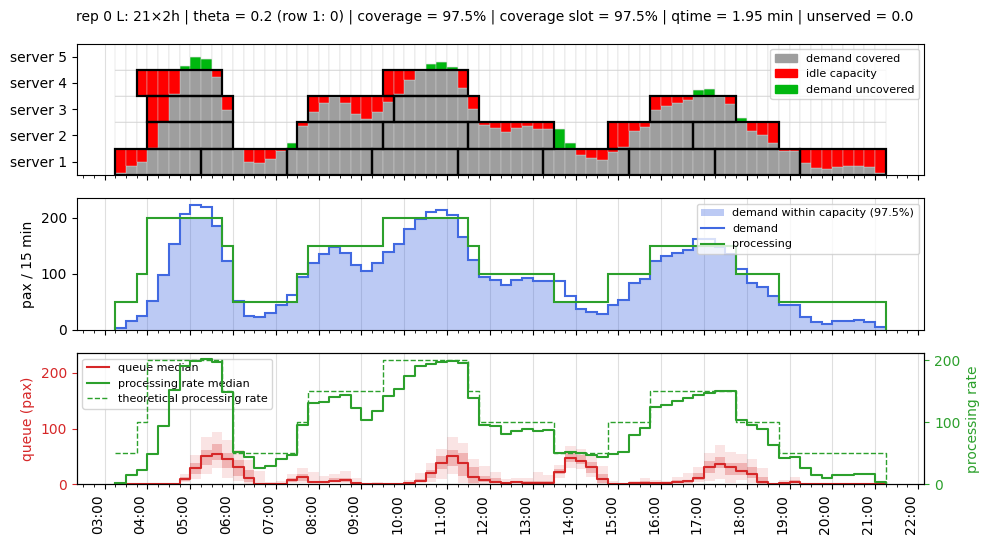

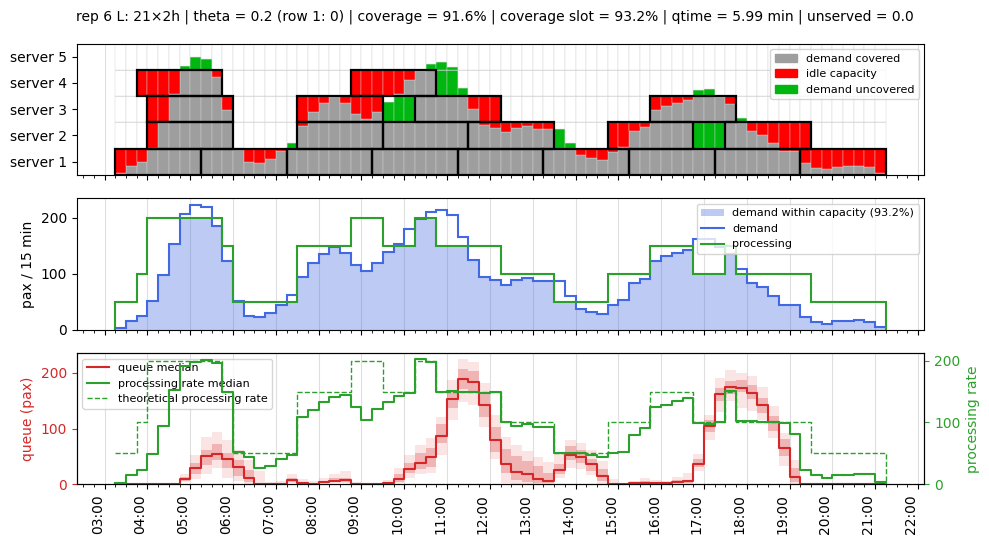

In [5]:
ctx = plotutils.load_context(os.path.join("data", f"context_{date.date()}.npz"))

r_a = df_pert[(df_pert["theta"] == 0.2) & (df_pert["rep_theta"] == 0)].iloc[0]
r_b = df_pert[(df_pert["theta"] == 0.2) & (df_pert["rep_theta"] == 6)].iloc[0]

ymax = max(sb.timeline_to_df(r["timeline"])["queue_length_p95"].max() for r in (r_a, r_b)) * 1.05

plotutils.plot_row(r_a, ctx, show_second=True, queue_max=ymax)
plotutils.plot_row(r_b, ctx, show_second=True, queue_max=ymax)

2026-10-28 12:37:40,316 | WARNING | app.services.preprocessing | More than 10% of flights (12/62) fall back to the unknown arrival sampler. Check the arrival model coverage.
2026-10-28 12:37:41,833 | INFO | app.services.security_class | [SecuritySimulator] Launching pool: 50 total tasks, 4 workers
2026-10-28 12:37:50,945 | INFO | app.services.security_class | [SecuritySimulator] Launching pool: 50 total tasks, 4 workers


a: qtime=1.98 (df: 1.95)  unserved=0.0 (df: 0.0)
b: qtime=6.03 (df: 5.99)  unserved=0.0 (df: 0.0)


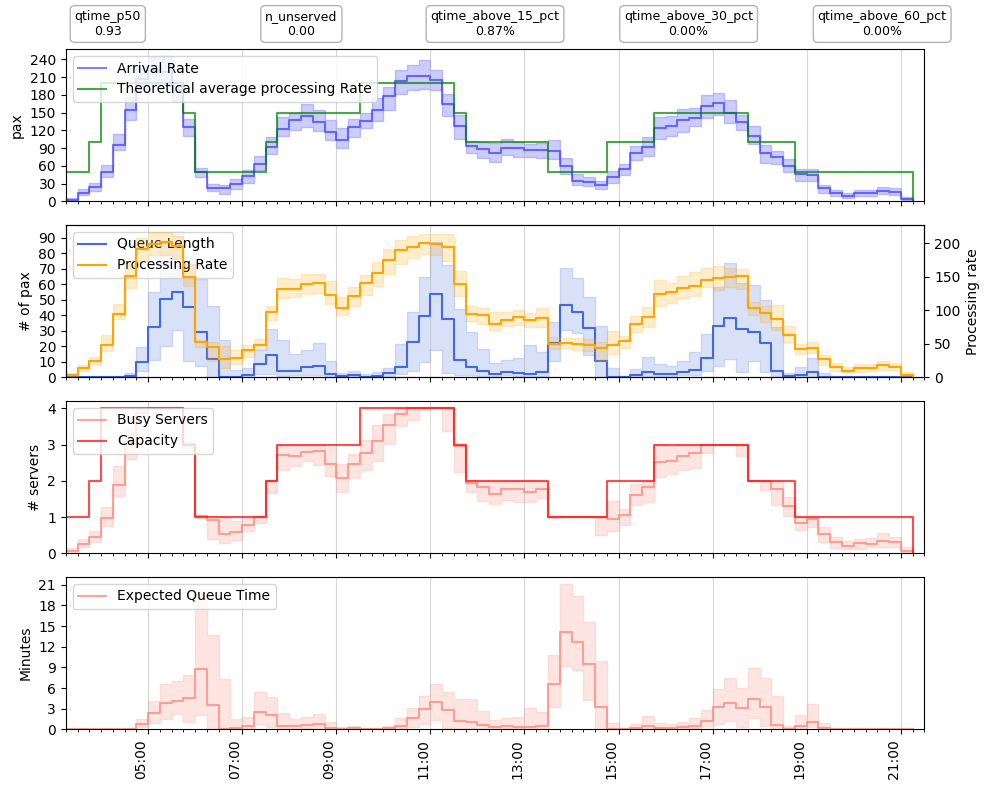

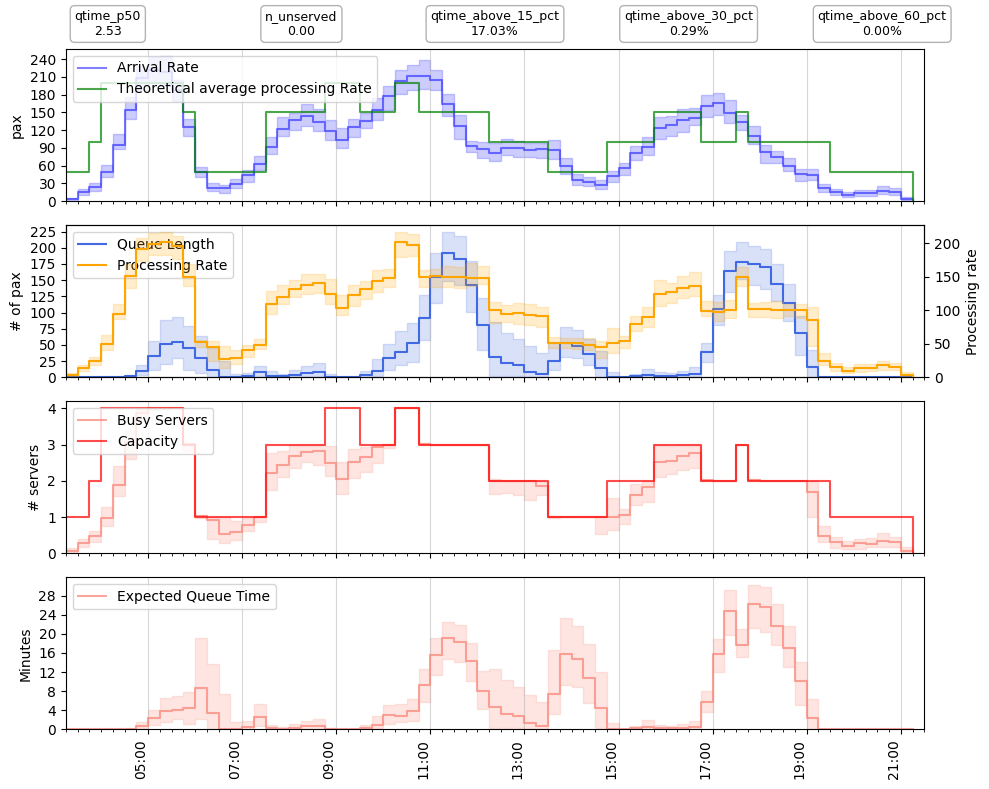

In [6]:
def simulate_row(row, ctx, n_scenarios=50, n_workers=4, timebin=15, base_seed=base_seed):
    blocks = plotutils.parse_blocks(row["blocks"])
    t0 = ctx["time_values"].iloc[0]
    step = pd.Timedelta(minutes=ctx["bin_minutes"])
    server_schedule = {
        lane: [((t0 + s * step).to_pydatetime(), (t0 + (s + n) * step).to_pydatetime()) for s, n in bl]
        for lane, bl in blocks.items() if len(bl)
    }
    sim = security_class.SecuritySimulator(
        flight_demand=flight_demand,
        intervals=utils.server_schedule_to_intervals(server_schedule),
        server_registry=server_registry)
    return sim.run(n_scenarios=n_scenarios, n_workers=n_workers, timebin=timebin, base_seed=base_seed)

schedule_or= pd.read_excel(os.path.join('data', 'schedule.xlsx'))
schedule_std= preprocessing.preprocess_schedule_FLR(schedule_or, profile_specs={})
schedule_f = schedule_std[schedule_std["date"] == date].copy()
schedule_pred = predictive.predict_pax(df=schedule_f, path=f"data/pax_model.joblib")
arrival_model = arrival_flow.load_arrival_flow(os.path.join("data", "arrival_flow.pt"))
flight_demand = preprocessing.build_flight_demand(schedule_pred, arrival_model=arrival_model)
registry={
    1: {'label': '1', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    2: {'label': '2', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    3: {'label': '3', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    4: {'label': '4', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    5: {'label': '5', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    6: {'label': '6', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    }
server_registry = preprocessing.build_processing_params_by_server(registry)

sim_a = simulate_row(r_a, ctx)
sim_b = simulate_row(r_b, ctx)

for name, r, s in (("a", r_a, sim_a), ("b", r_b, sim_b)):
    k = s.df_kpis.iloc[0]
    print(f"{name}: qtime={k.qtime_mean:.2f} (df: {r.qtime_mean:.2f})  "
          f"unserved={k.n_unserved:.1f} (df: {r.n_unserved:.1f})")

plotutils.plot_simulation(sim_a.df_timeline, sim_a.df_kpis)
plotutils.plot_simulation(sim_b.df_timeline, sim_b.df_kpis)

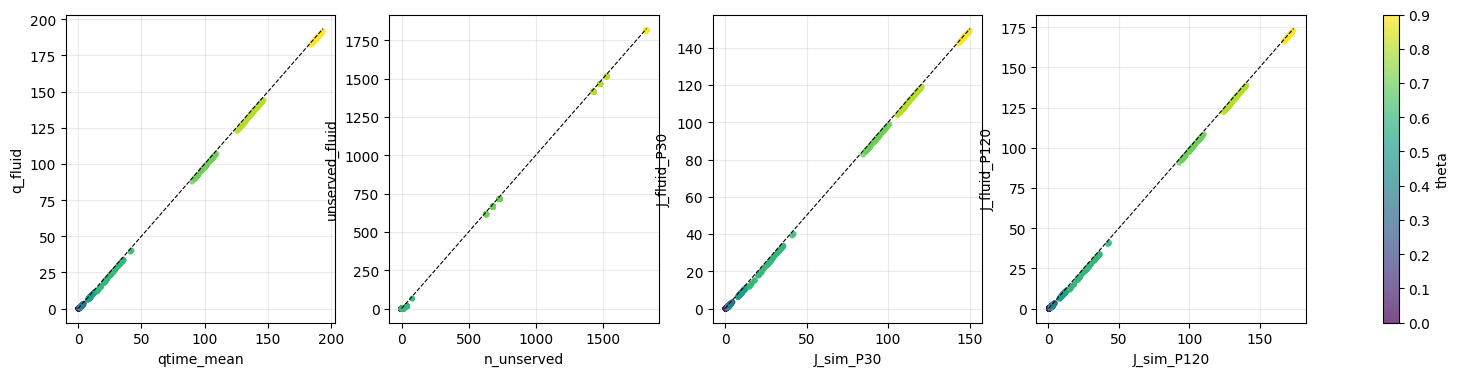

In [50]:
combs= [("qtime_mean", "q_fluid"), ("n_unserved", "unserved_fluid"),
                            ("J_sim_P30", "J_fluid_P30"),
                            ("J_sim_P120", "J_fluid_P120")]

fig, axs = plt.subplots(1, len(combs), figsize=(len(combs) * 5, 4))
for ax, (x, y) in zip(axs, combs):
    sc = ax.scatter(df_pert[x], df_pert[y], c=df_pert['theta'], s=10, alpha=0.7)
    lim = [0, max(df_pert[x].max(), df_pert[y].max())]
    ax.plot(lim, lim, "k--", lw=0.8)
    ax.set_xlabel(x); ax.set_ylabel(y); ax.grid(alpha=0.25)
plt.colorbar(sc, ax=axs, label="theta")
plt.show()

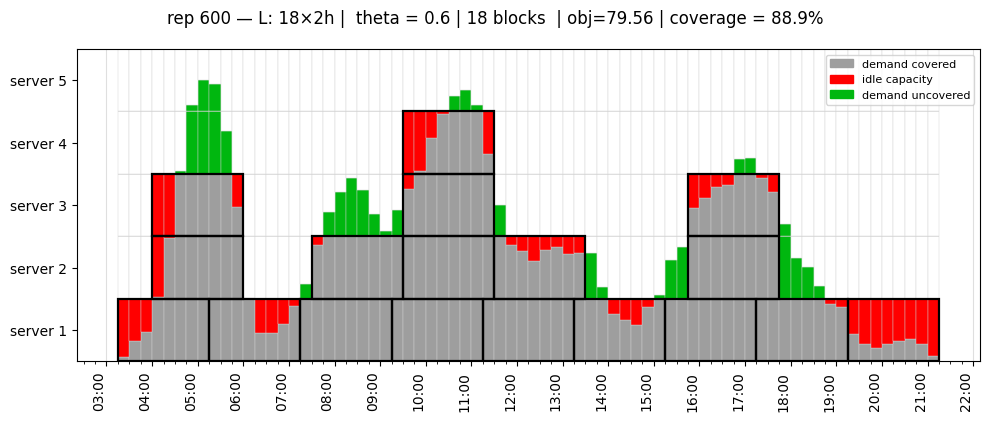

In [54]:
# modify solution

ctx = plotutils.load_context(os.path.join("data", f"context_{date.date()}.npz"))
labels = ctx["labels"][:ctx["D"].shape[0]]
T = ctx["D"].shape[1]

row = df_pert[(df_pert["theta"] == 0.6) & (df_pert["rep_theta"] == 0)].iloc[0]
blocks = plotutils.parse_blocks(row["blocks"])

plotutils.plot_row(row, ctx, show_second=False)

In [60]:
cov = plotutils.coverage_mask(new_blocks, labels, D.shape)
print(row["theta"] * cov[0].sum(), row["objective"] - obj)

43.199999999999996 43.2


coverage 88.82% (was 88.85%) | obj 79.51 (was 79.56) | fluid q=10.86 min, unserved=0.0 (was 25.10, 0.0)


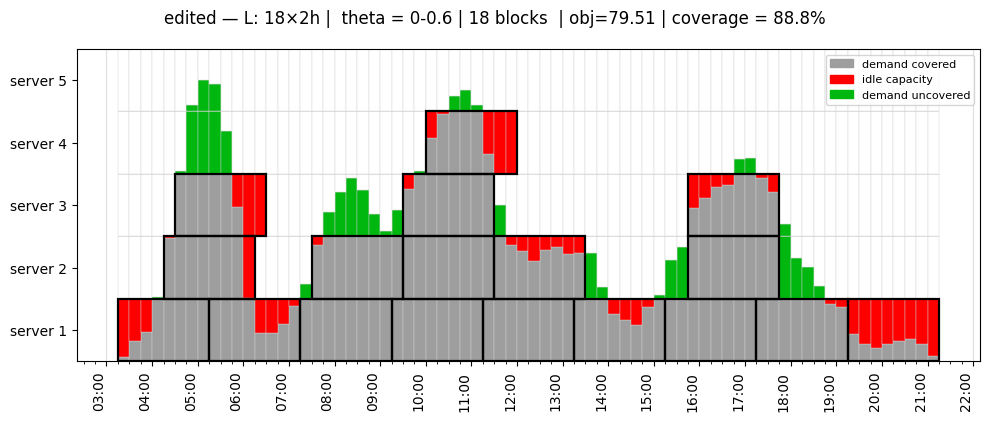

2026-10-26 15:55:31,490 | INFO | app.services.security_class | [SecuritySimulator] Launching pool: 50 total tasks, 4 workers


avg queue time 14.41 min, unserved 0.8 (was 27.47, 15.8)


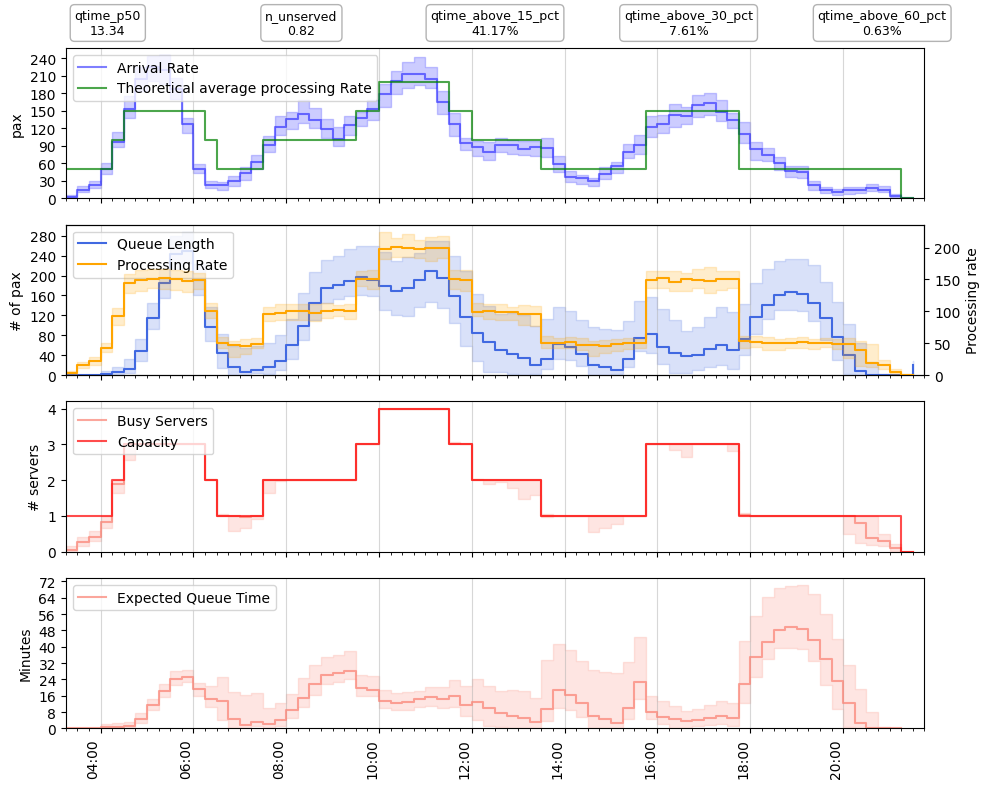

In [68]:
from app.services.perturbation import *
new_blocks, log = edit_blocks(
    blocks, labels,
    edits=[dict(lane="2", block=0, shift=1),
           dict(lane="3", block=0, shift=2),
           dict(lane="4", block=0, shift=2),],
    T=T,
    add=[])

D = ctx["D"]
theta_vec = np.full(D.shape[0], row["theta"])
theta_vec[0] = theta_first
cov, obj, coverage = plotutils.coverage_from_arrays(D, new_blocks, labels, theta_vec)
q_f, u_f = ls.fluid_metrics(ctx["arrivals"], ctx["rate_by_label"], new_blocks, ctx["bin_minutes"])
print(f"coverage {coverage:.2%} (was {row['coverage']:.2%}) | obj {obj:.2f} (was {row['objective']:.2f}) | "
      f"fluid q={q_f:.2f} min, unserved={u_f:.1f} (was {row['q_fluid']:.2f}, {row['unserved_fluid']:.1f})")

proc = plotutils.processing_from_blocks(new_blocks, ctx["rate_by_label"], T)
plotutils.plot_blocks(D, new_blocks, labels, ctx["time_values"], theta_vec, ctx["bin_minutes"],
               demand_curve=ctx["arrivals"], processing_curve=proc, show_second=False,
               title_prefix="edited")

t0, step = ctx["time_values"].iloc[0], pd.Timedelta(minutes=ctx["bin_minutes"])
server_schedule = {
    lane: [((t0 + s * step).to_pydatetime(), (t0 + (s + n) * step).to_pydatetime()) for s, n in bl]
    for lane, bl in new_blocks.items() if len(bl)
}

classe2 = security_class.SecuritySimulator(
    flight_demand=flight_demand,
    intervals=utils.server_schedule_to_intervals(server_schedule),
    server_registry=server_registry)

sim_results = classe2.run(n_scenarios=50, n_workers=4, timebin=15, base_seed=base_seed)
q_sim = float(sim_results.df_kpis.qtime_mean.iloc[0])
n_unserved = float(sim_results.df_kpis.n_unserved.iloc[0])
print(f"avg queue time {q_sim:.2f} min, unserved {n_unserved:.1f} (was {row['qtime_mean']:.2f}, {row['n_unserved']:.1f})")
plotutils.plot_simulation(sim_results.df_timeline, sim_results.df_kpis)

#### Full MILP

In [118]:
from app.services.full_milp import *
import app.services.local_search as ls

schedule_or= pd.read_excel(os.path.join('data', 'schedule.xlsx'))
schedule_std= preprocessing.preprocess_schedule_FLR(schedule_or, profile_specs={})
schedule_f = schedule_std[schedule_std["date"] == date].copy()

schedule_pred = predictive.predict_pax(df=schedule_f, path=f"data/pax_model.joblib")
arrival_model = arrival_flow.load_arrival_flow(os.path.join("data", "arrival_flow.pt"))

flight_demand = preprocessing.build_flight_demand(schedule_pred, arrival_model=arrival_model)

registry={
    1: {'label': '1', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    2: {'label': '2', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    3: {'label': '3', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    4: {'label': '4', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    5: {'label': '5', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    6: {'label': '6', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    }
server_registry = preprocessing.build_processing_params_by_server(registry)
arrivals= security_class.expected_arrivals(flight_demand)
planner = security_class.SecurityPlanner(arrivals, server_registry)

2026-10-26 16:30:57,544 | WARNING | app.services.preprocessing | More than 10% of flights (12/62) fall back to the unknown arrival sampler. Check the arrival model coverage.


In [119]:
df_results=pd.DataFrame()

status=None  gap=-0.00%  windows=20  obj/pax=0.67  unserved=0.0


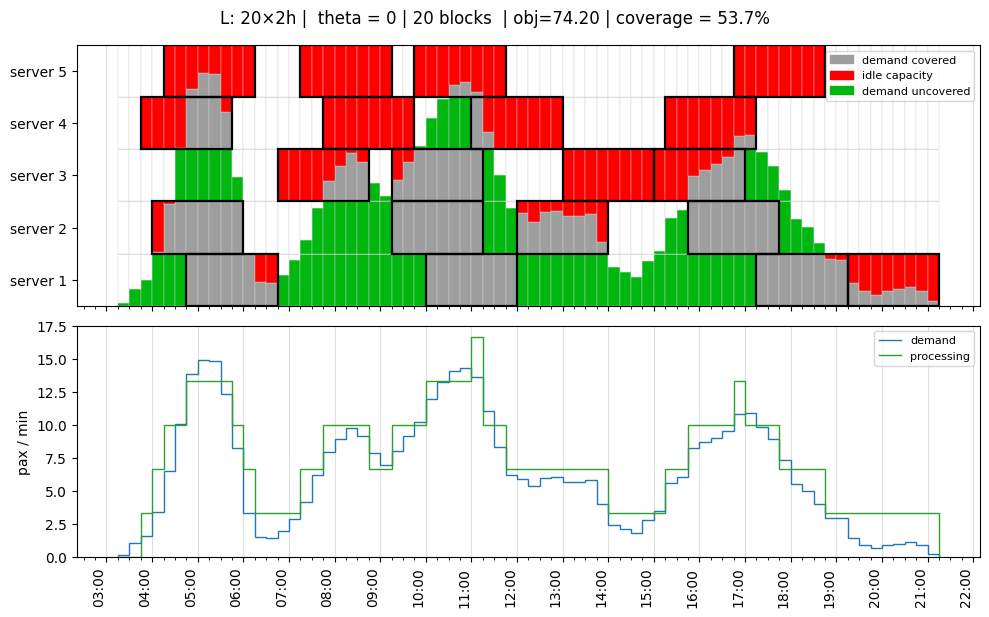

2026-10-26 16:31:07,694 | INFO | app.services.security_class | [SecuritySimulator] Launching pool: 50 total tasks, 4 workers


avg queue time 1.60 min, unserved 0.0


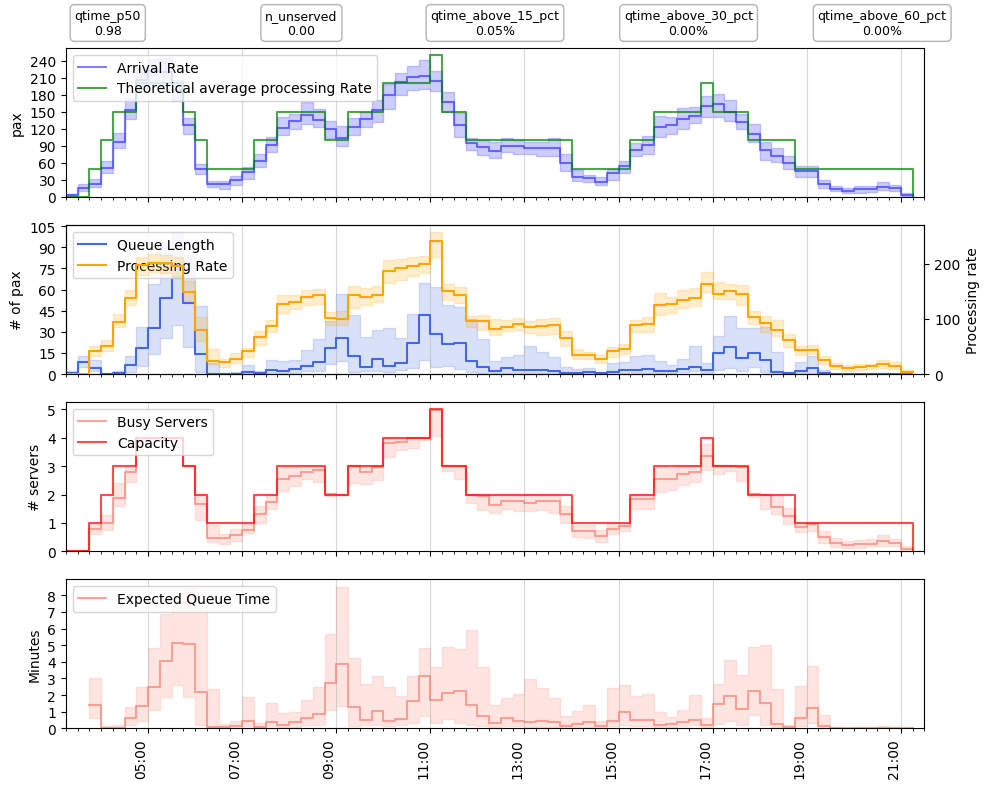

In [120]:
# get optimal schedule from MILP

lengths=[2]
length_totals={2:20}
K_total=1000

res_milp, info = run_fluid_milp(
    planner,
    lengths=lengths,
    K_total=K_total,
    length_totals=length_totals,
    penalty=240,
    time_limit=120
)

print(f"status={info['status']}  gap={info['gap']:.2%}  windows={info['n_windows']}  "
      f"obj/pax={info['objective_per_pax']:.2f}  unserved={info['unserved']:.1f}")

blocks_milp = schedule_to_blocks(planner, res_milp)
plotutils.plot_allocation(res_milp, show_second=True)

# evuluate the MILP solution with the simulator
sim_milp = security_class.SecuritySimulator(
    flight_demand=flight_demand,
    intervals=utils.server_schedule_to_intervals(res_milp.server_schedule),
    server_registry=server_registry)

sim_results_milp = sim_milp.run(n_scenarios=50, n_workers=4, timebin=15, base_seed=base_seed)
q_sim = float(sim_results_milp.df_kpis.qtime_mean.iloc[0])
n_unserved = float(sim_results_milp.df_kpis.n_unserved.iloc[0])
print(f"avg queue time {q_sim:.2f} min, unserved {n_unserved:.1f}")
row={
    "date": date, "lengths": str(lengths), "length_totals": str(length_totals), "K_total": K_total,
    "n_windows": info["n_windows"], "method": "MILP", "gap": info["gap"],
    "q_sim": q_sim, "unserved_sim": n_unserved
}
df_results = pd.concat([df_results, pd.DataFrame([row])], ignore_index=True)
plotutils.plot_simulation(sim_results_milp.df_timeline, sim_results_milp.df_kpis)

2026-10-26 16:29:08,364 | INFO | app.services.security_class | [SecurityPlanner] Launching multi-length allocation: lengths=[2.0] h, theta=0.90


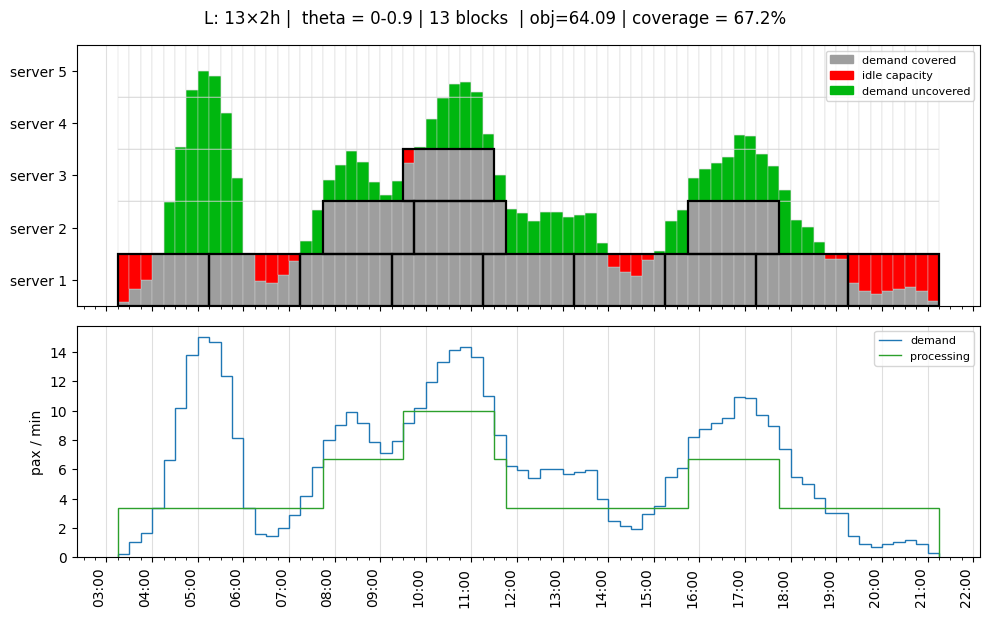

2026-10-26 16:29:10,244 | INFO | app.services.security_class | [SecuritySimulator] Launching pool: 50 total tasks, 4 workers


avg queue time 188.81 min, unserved 1825.6


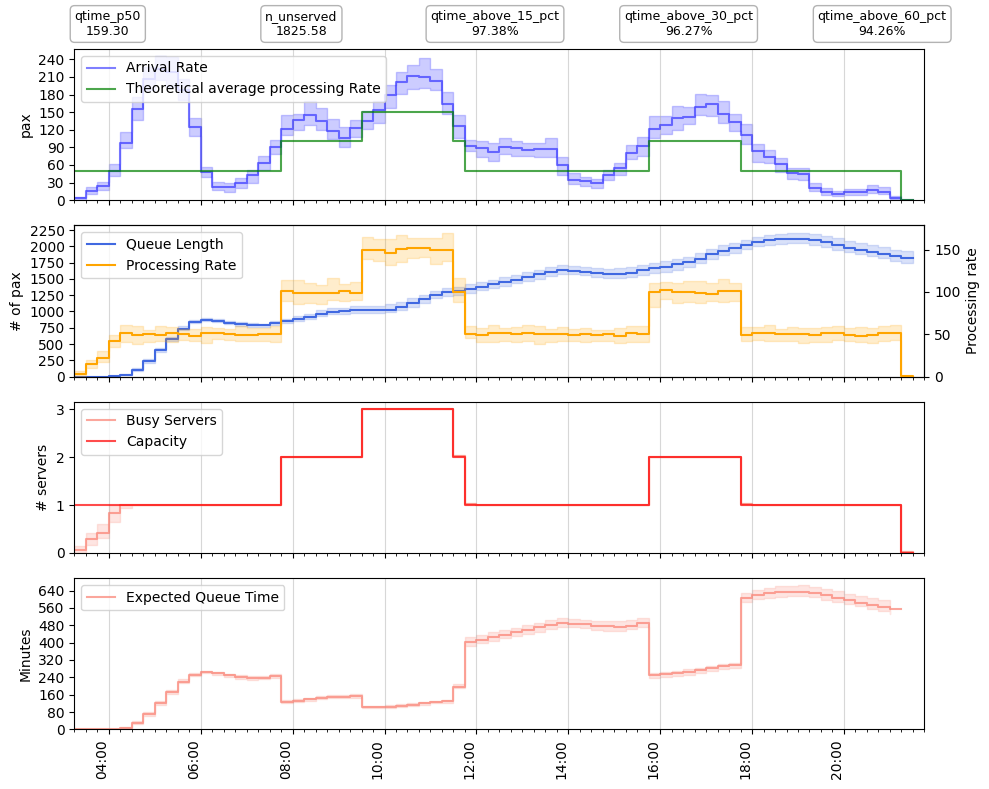

In [116]:
# use same budgets with our DP+MILP approach
theta = 0.9

res_dp = planner.run_multi(lengths=lengths, length_totals=length_totals, theta=theta, K_total=K_total, theta_first=0)
blocks_dp = schedule_to_blocks(planner, res_dp)
plotutils.plot_allocation(res_dp, show_second=True)

# evaluate the DP+MILP solution with the simulator
sim_dp = security_class.SecuritySimulator(
    flight_demand=flight_demand,
    intervals=utils.server_schedule_to_intervals(res_dp.server_schedule),
    server_registry=server_registry)

sim_results_dp = sim_dp.run(n_scenarios=50, n_workers=4, timebin=15, base_seed=base_seed)
q_sim = float(sim_results_dp.df_kpis.qtime_mean.iloc[0])
n_unserved = float(sim_results_dp.df_kpis.n_unserved.iloc[0])
print(f"avg queue time {q_sim:.2f} min, unserved {n_unserved:.1f}")
plotutils.plot_simulation(sim_results_dp.df_timeline, sim_results_dp.df_kpis)

In [ ]:
# use same budgets with our DP+MILP approach

for theta_i in np.arange(0.0, 1, 0.1):
    theta_i = round(float(theta_i), 6)

    res_dp = planner.run_multi(lengths=lengths, length_totals=length_totals, theta=theta_i, K_total=K_total, theta_first=0)
    blocks_dp = schedule_to_blocks(planner, res_dp)

    # evaluate the DP+MILP solution with the simulator
    sim_dp = security_class.SecuritySimulator(
        flight_demand=flight_demand,
        intervals=utils.server_schedule_to_intervals(res_dp.server_schedule),
        server_registry=server_registry)

    sim_results_dp = sim_dp.run(n_scenarios=50, n_workers=4, timebin=15, base_seed=base_seed)
    q_sim = float(sim_results_dp.df_kpis.qtime_mean.iloc[0])
    n_unserved = float(sim_results_dp.df_kpis.n_unserved.iloc[0])
    print(f"avg queue time {q_sim:.2f} min, unserved {n_unserved:.1f}")
    row={
        "date": date, "lengths": str(lengths), "length_totals": str(length_totals), "K_total": K_total,
        "n_windows": planner.report.total.n_blocks, "method": "DP+MILP", "theta": theta_i,
        "q_sim": q_sim, "unserved_sim": n_unserved
    }
    df_results = pd.concat([df_results, pd.DataFrame([row])], ignore_index=True)

In [132]:
from app.services.simulation_batch import simulate_kpis
N_pax = float(planner.arrivals.sum())
PENALTIES = [30, 60, 120, 240]

res_list, meta = [], []
for theta_i in np.round(np.arange(0.0, 0.8, 0.1), 6):
    r = planner.run_multi(lengths=lengths, length_totals=length_totals, theta=float(theta_i),
                          K_total=K_total, theta_first=0)
    res_list.append(r)
    meta.append(dict(theta=theta_i, theta_first=0, n_windows=int(planner.report.total.n_blocks)))

# MILP: stesse finestre del DP (frontiera) + il caso con tutte le 20
milp_runs = []
for n_w in sorted({m["n_windows"] for m in meta} | {20}):
    r, info = run_fluid_milp(planner, lengths=lengths, K_total=K_total,
                             length_totals={lengths[0]: n_w}, penalty=240, time_limit=150)
    res_list.append(r)
    meta.append(dict(method="MILP", n_windows=n_w, gap=info["gap"]))

intervals_list = [utils.server_schedule_to_intervals(r.server_schedule) for r in res_list]
kpis = simulate_kpis(flight_demand, intervals_list, server_registry,
                     n_scenarios=50, n_workers=os.cpu_count(), timebin=15, base_seed=base_seed)

rows = []
for m, k in zip(meta, kpis.itertuples()):
    q, u = k.qtime_mean, k.n_unserved
    row = dict(m)
    row.setdefault("method", "DP+MILP")        # le righe MILP hanno già "method"
    row.update(q_sim=q, unserved_sim=u,
               **{f"J_sim_P{P}": ((N_pax - u) * q + P * u) / N_pax for P in PENALTIES})
    rows.append(row)
df_results = pd.concat([df_results, pd.DataFrame(rows)], ignore_index=True)

2026-10-26 16:43:05,972 | INFO | app.services.security_class | [SecurityPlanner] Launching multi-length allocation: lengths=[2.0] h, theta=0.00
2026-10-26 16:43:06,001 | INFO | app.services.security_class | [SecurityPlanner] Launching multi-length allocation: lengths=[2.0] h, theta=0.10
2026-10-26 16:43:06,046 | INFO | app.services.security_class | [SecurityPlanner] Launching multi-length allocation: lengths=[2.0] h, theta=0.20
2026-10-26 16:43:06,077 | INFO | app.services.security_class | [SecurityPlanner] Launching multi-length allocation: lengths=[2.0] h, theta=0.30
2026-10-26 16:43:06,109 | INFO | app.services.security_class | [SecurityPlanner] Launching multi-length allocation: lengths=[2.0] h, theta=0.40
2026-10-26 16:43:06,146 | INFO | app.services.security_class | [SecurityPlanner] Launching multi-length allocation: lengths=[2.0] h, theta=0.50
2026-10-26 16:43:06,174 | INFO | app.services.security_class | [SecurityPlanner] Launching multi-length allocation: lengths=[2.0] h, the

In [133]:
df_results

,date,lengths,length_totals,K_total,n_windows,method,gap,q_sim,unserved_sim,theta,theta_first,J_sim_P30,J_sim_P60,J_sim_P120,J_sim_P240
0,2026-06-01,[2],{2: 20},1000.0,20.0,MILP,-4.300920e-09,1.599610,0.00,NaN,NaN,NaN,NaN,NaN,NaN
1,2026-06-01,[2],{2: 20},1000.0,20.0,DP+MILP,NaN,2.023959,91.06,0.0,NaN,NaN,NaN,NaN,NaN
2,2026-06-01,[2],{2: 20},1000.0,20.0,DP+MILP,NaN,1.937788,91.06,0.1,NaN,NaN,NaN,NaN,NaN
3,2026-06-01,[2],{2: 20},1000.0,20.0,DP+MILP,NaN,2.023959,91.06,0.2,NaN,NaN,NaN,NaN,NaN
4,2026-06-01,[2],{2: 20},1000.0,20.0,DP+MILP,NaN,7.231231,0.00,0.3,NaN,NaN,NaN,NaN,NaN
5,2026-06-01,[2],{2: 20},1000.0,20.0,DP+MILP,NaN,7.234848,0.00,0.4,NaN,NaN,NaN,NaN,NaN
6,2026-06-01,[2],{2: 20},1000.0,19.0,DP+MILP,NaN,10.200343,0.00,0.5,NaN,NaN,NaN,NaN,NaN
7,2026-06-01,[2],{2: 20},1000.0,18.0,DP+MILP,NaN,27.624361,16.10,0.6,NaN,NaN,NaN,NaN,NaN
8,2026-06-01,[2],{2: 20},1000.0,16.0,DP+MILP,NaN,100.004532,681.74,0.7,NaN,NaN,NaN,NaN,NaN
9,2026-06-01,[2],{2: 20},1000.0,14.0,DP+MILP,NaN,136.438771,1480.88,0.8,NaN,NaN,NaN,NaN,NaN


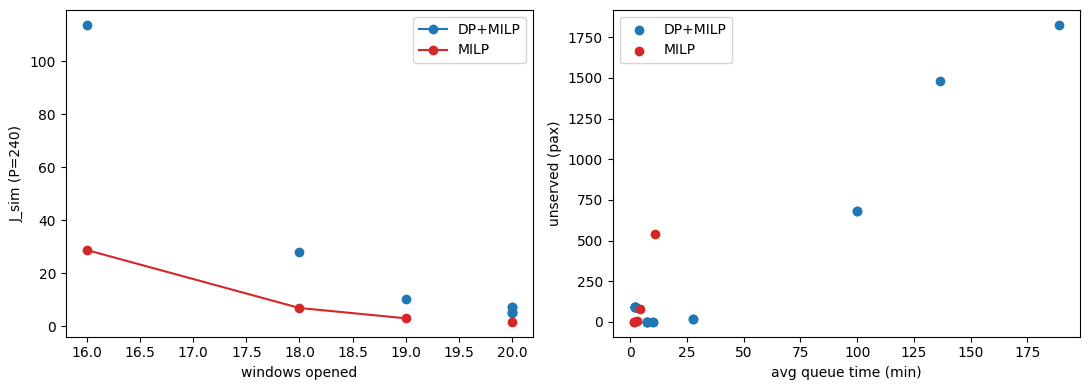

In [134]:
d = df_results
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for m, c in (("DP+MILP", "tab:blue"), ("MILP", "tab:red")):
    s = d[d["method"] == m].sort_values("n_windows")
    ax[0].plot(s["n_windows"], s["J_sim_P240"], "o-", color=c, label=m)
    ax[1].scatter(s["q_sim"], s["unserved_sim"], color=c, label=m)
ax[0].set(xlabel="windows opened", ylabel="J_sim (P=240)"); ax[0].legend()
ax[1].set(xlabel="avg queue time (min)", ylabel="unserved (pax)"); ax[1].legend()
plt.tight_layout()

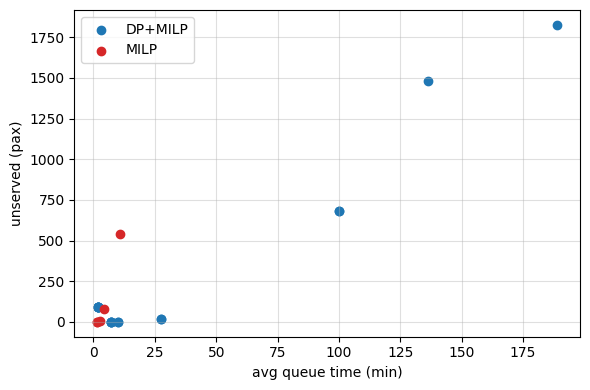

In [135]:
d = df_results
fig, ax = plt.subplots(figsize=(6, 4))
for m, c in (("DP+MILP", "tab:blue"), ("MILP", "tab:red")):
    s = d[d["method"] == m].sort_values("n_windows")
    ax.scatter(s["q_sim"], s["unserved_sim"], color=c, label=m)
ax.set(xlabel="avg queue time (min)", ylabel="unserved (pax)")
plt.grid(alpha=0.4)
ax.legend()
plt.tight_layout()
plt.show()

In [117]:
df_results

,date,lengths,length_totals,K_total,n_windows,method,gap,q_sim,unserved_sim,theta
0,2026-06-01,[2],{2: 20},1000,20.0,MILP,-4.283548e-09,1.576761,0.00,NaN
1,2026-06-01,[2],{2: 20},1000,13.0,DP+MILP,NaN,188.813488,1825.58,0.9


#### pipeline

2026-10-23 16:58:24,727 | WARNING | app.services.preprocessing | More than 10% of flights (12/62) fall back to the unknown arrival sampler. Check the arrival model coverage.
2026-10-23 16:58:24,734 | INFO | app.services.security_class | [SecurityPlanner] Launching multi-length allocation: lengths=[2.0] h, alpha=0.70


running baseline


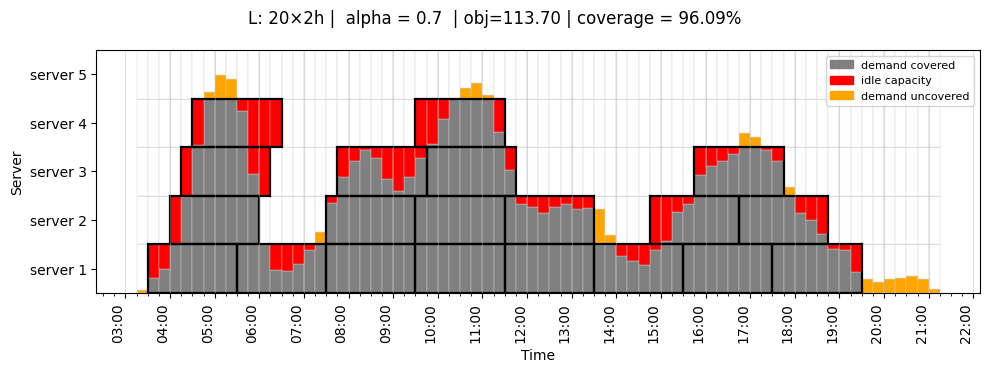

In [59]:
date=dt.datetime(2026, 6, 1)
alpha = 0.7
lengths=[2]
length_totals={2:20}
K_total=100
P=240

schedule_or = pd.read_excel(os.path.join('data', 'schedule.xlsx'))
schedule_std = preprocessing.preprocess_schedule_FLR(schedule_or, profile_specs={})
schedule_f = schedule_std[schedule_std["date"] == date].copy()

schedule_pred = predictive.predict_pax(df=schedule_f, path=f"data/pax_model.joblib")
arrival_model = arrival_flow.load_arrival_flow(os.path.join("data", "arrival_flow.pt"))
flight_demand = preprocessing.build_flight_demand(schedule_pred, arrival_model=arrival_model)

registry={
    1: {'label': '1', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    2: {'label': '2', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    3: {'label': '3', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    4: {'label': '4', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    5: {'label': '5', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    6: {'label': '6', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    }
server_registry = preprocessing.build_processing_params_by_server(registry)

print("running baseline")
arrivals= security_class.expected_arrivals(flight_demand)
planner = security_class.SecurityPlanner(arrivals, server_registry)
res = planner.run_multi(lengths=lengths, length_totals=length_totals, alpha=alpha, K_total=K_total)
plotutils.plot_allocation(res, show_second=False)

In [104]:
def penalized_wait(q, u, P, N):
    """Mean wait per passenger, each unserved passenger counted as P minutes."""
    return ((N - u) * q + P * u) / N

N_pax = float(planner.arrivals.sum())

In [86]:
_EDIT_KEYS = {"lane", "block", "shift", "length", "remove"}

def edit_blocks(blocks, labels, edits, T, add=None):
    """
    Modifica a mano una schedule {label: [(start_slot, length_slots), ...]}.

    edits : lista di dict, uno per blocco da cambiare
              lane   : etichetta ('3') oppure posizione 0-based in `labels`
              block  : indice 0-based del blocco nella lane (ordinato per start; riferito alla baseline)
              shift  : slot di spostamento (+ = piu' tardi), default 0
              length : nuova lunghezza in slot (opzionale), lo start resta quello dopo lo shift
              remove : True per eliminare il blocco
    add   : lista di dict(lane=..., start=..., length=...) con nuovi blocchi (slot, 0-based)
    T     : numero di slot del giorno; ogni blocco deve stare in [0, T] e non sovrapporsi nella lane.
    Ritorna (new_blocks, log). Solleva ValueError se una modifica non e' valida.
    """
    labels = list(labels)

    def lane_of(x):
        if isinstance(x, str):
            if x not in labels and x not in blocks:
                raise ValueError(f"unknown lane {x!r}; lanes are {labels}")
            return x
        i = int(x)
        if not 0 <= i < len(labels):
            raise ValueError(f"lane index {i} out of range 0..{len(labels) - 1} ({labels})")
        return labels[i]

    cur = {k: [[int(s), int(l)] for s, l in v] for k, v in blocks.items()}
    log, touched = [], set()
    for e in edits or []:
        bad = set(e) - _EDIT_KEYS
        if bad:
            raise ValueError(f"unknown keys {sorted(bad)} in edit {e}; allowed: {sorted(_EDIT_KEYS)}")
        lab, i = lane_of(e["lane"]), int(e["block"])
        n = len(cur.get(lab, []))
        if not 0 <= i < n:
            raise ValueError(f"lane {lab!r} has {n} blocks (0..{n - 1}); block={i}")
        if (lab, i) in touched:
            raise ValueError(f"block {i} of lane {lab!r} is edited twice")
        touched.add((lab, i))
        if e.get("remove"):
            log.append(f"{lab} block {i}: removed {tuple(cur[lab][i])}")
            cur[lab][i] = None
            continue
        s, l = cur[lab][i]
        shift, new_len = int(e.get("shift", 0)), e.get("length")
        s2, l2 = s + shift, (l if new_len is None else int(new_len))
        cur[lab][i] = [s2, l2]
        log.append(f"{lab} block {i}: ({s},{l}) -> ({s2},{l2})")
    for a in add or []:
        lab = lane_of(a["lane"])
        cur.setdefault(lab, []).append([int(a["start"]), int(a["length"])])
        log.append(f"{lab}: added ({int(a['start'])},{int(a['length'])})")

    out = {}
    for lab, bl in cur.items():
        bl = sorted(tuple(b) for b in bl if b is not None)
        for s, l in bl:
            if l < 1 or s < 0 or s + l > T:
                raise ValueError(f"lane {lab!r}: block (start={s}, length={l}) is outside the day [0, {T}]")
        for (s1, l1), (s2, l2) in zip(bl, bl[1:]):
            if s2 < s1 + l1:
                raise ValueError(f"lane {lab!r}: blocks (start={s1}, length={l1}) and (start={s2}, length={l2}) overlap")
        if bl:
            out[lab] = bl
    return out, log

In [43]:
# import app.services.perturbation as pm

# T = len(planner.arrivals)
# blocks0 = pm.schedule_to_blocks(planner, res)

# new_blocks, log = edit_blocks(
#     blocks0, res.server_labels, edits=[], T=T,
#     add=[dict(lane='1', start=68, length=4)])
# print(*log, sep="\n")

# res_new = pm.res_with_blocks(planner, res, new_blocks)
# plotutils.plot_allocation(res_new, show_second=False)

2026-10-23 16:59:05,429 | INFO | app.services.security_class | [SecuritySimulator] Launching pool: 100 total tasks, 4 workers


Avg qtime: 1.9124364537697291, Unserved: 91.37, J_sim (P=240): 5.062


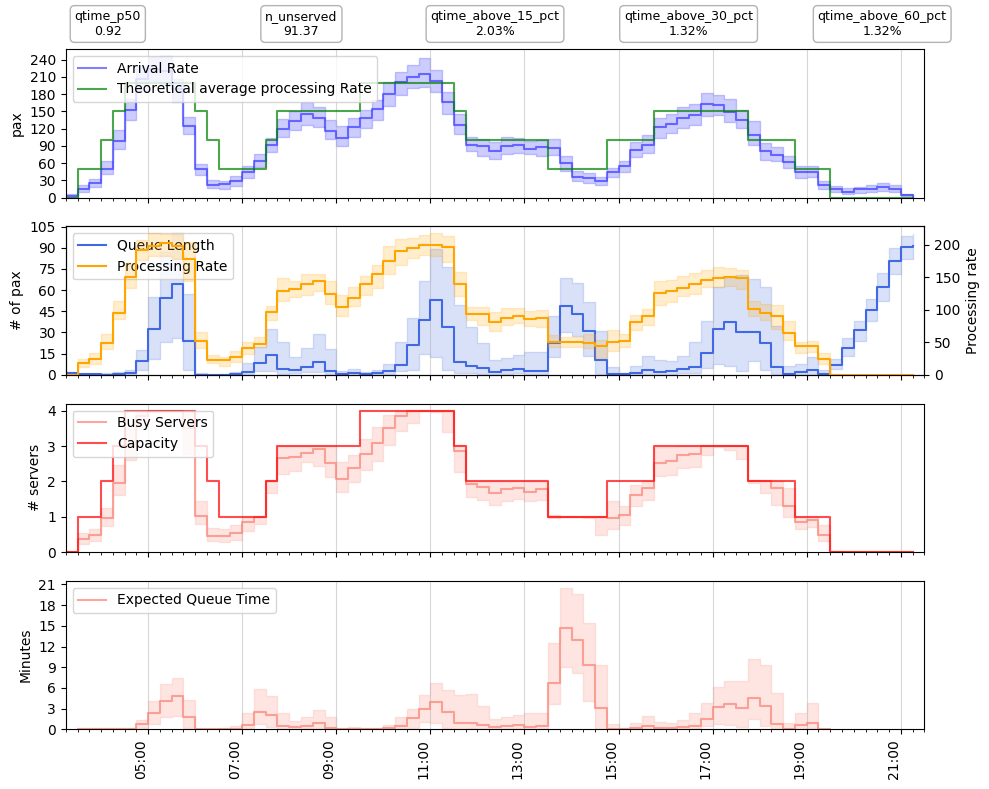

In [61]:
# valutazione baseline con simulator
classe2= security_class.SecuritySimulator(
    flight_demand=flight_demand,
    intervals=utils.server_schedule_to_intervals(res.server_schedule),
    server_registry=server_registry)

sim_results = classe2.run(n_scenarios=100, n_workers=4, timebin=15, base_seed=base_seed)
q_sim_base = float(sim_results.df_kpis.qtime_mean.iloc[0])
n_unserved_base = float(sim_results.df_kpis.n_unserved.iloc[0])
J_sim_base = penalized_wait(q_sim_base, n_unserved_base, P, N_pax)
print(f"Avg qtime: {q_sim_base}, Unserved: {n_unserved_base}, J_sim (P={P}): {J_sim_base:.3f}")
plotutils.plot_simulation(sim_results.df_timeline, sim_results.df_kpis)

In [45]:
# q_runs, unserved_runs = [], []
# arrival_runs, queue_runs = {}, {} 

# for i in range(21):
#     seed= i *1000
#     sim_results = classe2.run(n_scenarios=100, n_workers=4, timebin=15, base_seed=seed)
#     q = float(sim_results.df_kpis.qtime_mean.iloc[0])
#     u = float(sim_results.df_kpis.n_unserved.iloc[0])
#     q_runs.append(q)
#     unserved_runs.append(u)

#     tl = sim_results.df_timeline
#     if "timebin" in tl.columns:               # adatta il nome se la colonna del tempo si chiama diversamente
#         tl = tl.set_index("timebin")
#     arrival_runs[seed] = tl["arrival_rate_median"]
#     queue_runs[seed]   = tl["queue_length_median"]
#     print(f"seed={seed} | Avg qtime: {q:.3f}, Unserved: {u:.2f}")

# arrival_df = pd.concat(arrival_runs, axis=1)     # righe = time bin, colonne = seed
# queue_df   = pd.concat(queue_runs, axis=1)

# q_runs, unserved_runs = np.array(q_runs), np.array(unserved_runs)
# for name, x in [("qtime", q_runs), ("unserved", unserved_runs)]:
#     print(f"{name}: mean={x.mean():.3f}  std={x.std(ddof=1):.3f}  CV={x.std(ddof=1)/x.mean():.1%}  "
#           f"range=[{x.min():.3f}, {x.max():.3f}]")

# fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4), sharex=False)
# ax1.hist(q_runs, bins=10, alpha=0.7)
# ax2.hist(unserved_runs, bins=10, alpha=0.7)
# ax1.set_xlabel("Avg queue time [min]"); ax2.set_xlabel("Unserved pax")
# ax1.set_ylabel("Frequency"); ax2.set_ylabel("Frequency")
# ax1.set_title("Avg queue time over seeds"); ax2.set_title("Unserved over seeds")
# ax1.grid(alpha=0.3); ax2.grid(alpha=0.3)
# plt.tight_layout(); plt.show()

In [62]:
import app.services.local_search as ls
import app.services.perturbation as pm

T = len(planner.arrivals)
labels = res.server_labels
blocks0 = pm.schedule_to_blocks(planner, res)

best, trace = ls.local_search(
    planner.arrivals.to_numpy(), planner.rate_by_label, planner.demand_grid[:len(labels)],
    labels, alpha, blocks0, planner.bin_minutes,
    penalty=P,
    max_iter=500, max_shift=None, n_kicks=20)
trace

kick 12: improved -> unserved=0.00 q_fluid=2.570 J=2.570
kick 17: improved -> unserved=0.00 q_fluid=2.402 J=2.402
11 moves | unserved 90.97 -> 0.00 | q_fluid 0.929 -> 2.402 | J 4.077 -> 2.402 | coverage 0.961 -> 0.870


,iter,kick,move,q_fluid,unserved_fluid,covered_demand,idle_capacity,coverage,objective,J
0,0,0,None,0.928945,90.968,132.762936,27.237064,0.960936,113.696991,4.077152
1,1,0,"(2, 0, 64)",2.853857,0.000,125.779368,34.220632,0.910389,101.824926,2.853857
2,2,0,"(2, 2, 34)",2.693799,0.000,125.508862,34.491138,0.908431,101.365065,2.693799
3,3,0,"(2, 1, 26)",2.585227,0.000,125.508862,34.491138,0.908431,101.365065,2.585227
4,4,12,"(3, 3, 27)",5.570202,0.000,120.029038,39.970962,0.868768,92.049365,5.570202
5,5,12,"(1, 7, 57)",2.727895,0.000,124.201693,35.798307,0.898970,99.142878,2.727895
6,6,12,"(4, 1, 25)",2.589869,0.000,124.508862,35.491138,0.901193,99.665065,2.589869
7,7,12,"(2, 2, 35)",2.570180,0.000,123.869819,36.130181,0.896568,98.578692,2.570180
8,8,17,"(3, 3, 54)",6.316756,0.000,114.036207,45.963793,0.825392,81.861552,6.316756
9,9,17,"(2, 0, 5)",2.935107,0.000,117.783847,42.216153,0.852518,88.232540,2.935107


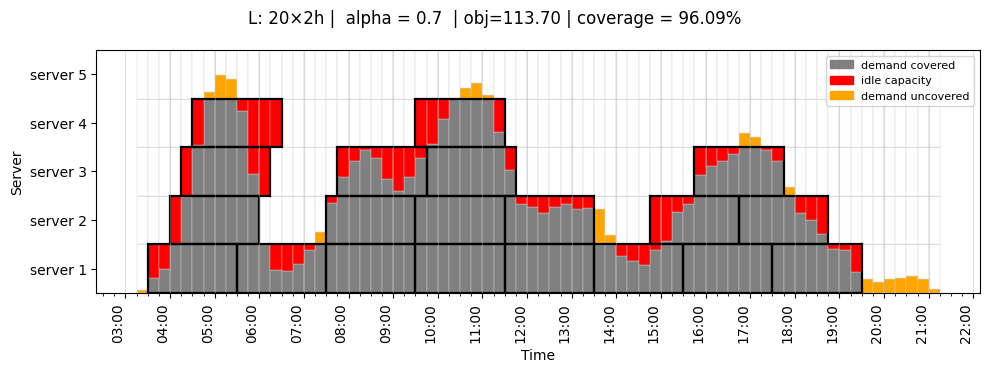

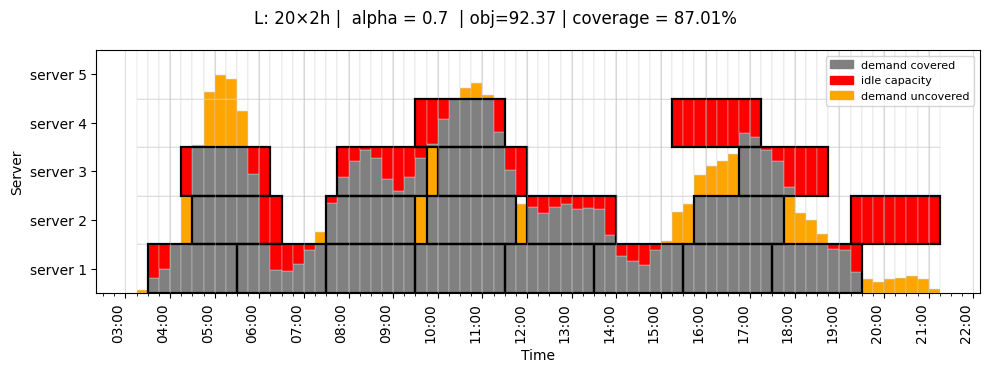

In [63]:
res_ls = pm.res_with_blocks(planner, res, best)
plotutils.plot_allocation(res, show_second=False)
plotutils.plot_allocation(res_ls, show_second=False)

2026-10-23 16:59:27,088 | INFO | app.services.security_class | [SecuritySimulator] Launching pool: 100 total tasks, 4 workers


Avg qtime: 3.7094501493126892, Unserved: 0.0, J_sim (P=240): 3.709


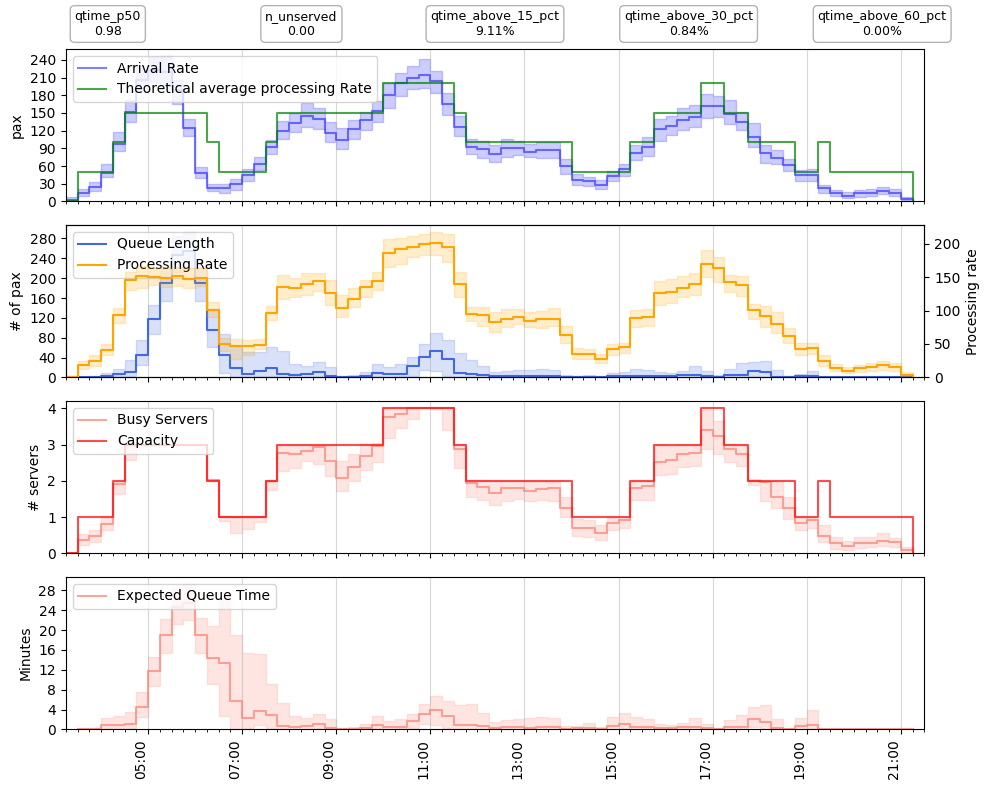

In [64]:
# valutazione baseline con simulator
classe2= security_class.SecuritySimulator(
    flight_demand=flight_demand,
    intervals=utils.server_schedule_to_intervals(res_ls.server_schedule),
    server_registry=server_registry)

sim_results = classe2.run(n_scenarios=100, n_workers=4, timebin=15, base_seed=base_seed)
q_sim_end = float(sim_results.df_kpis.qtime_mean.iloc[0])
n_unserved_end = float(sim_results.df_kpis.n_unserved.iloc[0])
J_sim_end = penalized_wait(q_sim_end, n_unserved_end, P, N_pax)
print(f"Avg qtime: {q_sim_end}, Unserved: {n_unserved_end}, J_sim (P={P}): {J_sim_end:.3f}")
plotutils.plot_simulation(sim_results.df_timeline, sim_results.df_kpis)

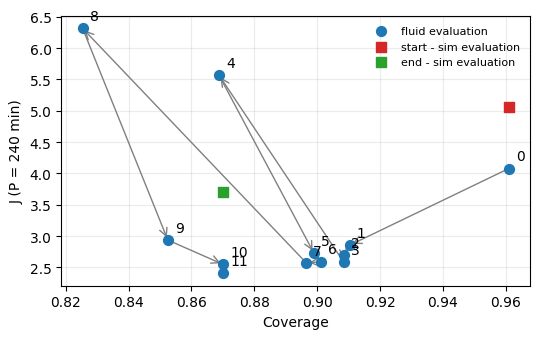

In [65]:
def plot_trace(trace, J_sim_base=None, J_sim_end=None, P=None, figsize=(5.5, 3.5)):
    x = trace["coverage"].to_numpy()
    y = trace["J"].to_numpy()                      # J fluido (richiede penalty=P nel local search)

    fig, ax = plt.subplots(figsize=figsize)
    ax.scatter(x, y, s=50, zorder=3, label="fluid evaluation")
    for i in range(len(trace) - 1):
        ax.annotate("", xy=(x[i+1], y[i+1]), xytext=(x[i], y[i]),
                    arrowprops=dict(arrowstyle="->", color="gray", lw=1, mutation_scale=14), zorder=2)
    for i, (xi, yi) in enumerate(zip(x, y)):
        ax.annotate(str(trace["iter"].iloc[i]), (xi, yi), xytext=(5, 6), textcoords="offset points")

    if J_sim_base is not None:
        ax.scatter([x[0]], [J_sim_base], s=50, marker="s", color="tab:red", zorder=4, label="start - sim evaluation")
    if J_sim_end is not None:
        ax.scatter([x[-1]], [J_sim_end], s=50, marker="s", color="tab:green", zorder=4, label="end - sim evaluation")

    ax.set_xlabel("Coverage")
    ax.set_ylabel(f"J (P = {P} min)" if P else "J")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8, frameon=False)
    plt.tight_layout()
    plt.show()

plot_trace(trace, J_sim_base, J_sim_end, P)

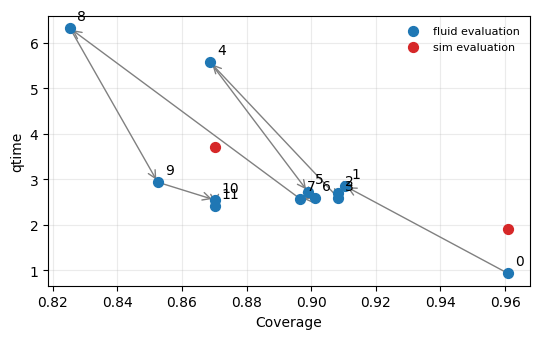

In [67]:
def plot_trace(trace, metric, q_sim_base=None, q_sim_end=None, n_unserved_base=None, n_unserved_end=None, figsize=(5.5, 3.5)):
    x = trace["coverage"].to_numpy()
    if metric == "qtime":
        y = trace["q_fluid"].to_numpy()
    elif metric == "unserved":
        y = trace["unserved_fluid"].to_numpy()

    fig, ax = plt.subplots(figsize=figsize)
    ax.scatter(x, y, s=50, zorder=3, label="fluid evaluation")
    for i in range(len(trace) - 1):
        ax.annotate("", xy=(x[i+1], y[i+1]), xytext=(x[i], y[i]),
                    arrowprops=dict(arrowstyle="->", color="gray", lw=1, mutation_scale=14), zorder=2)
    for i, (xi, yi) in enumerate(zip(x, y)):
        ax.annotate(str(trace["iter"].iloc[i]), (xi, yi), xytext=(5, 6), textcoords="offset points")

    if metric == "qtime":
        if q_sim_base is not None:
            ax.scatter([x[0]], [q_sim_base], s=50, color="tab:red", zorder=4, label="sim evaluation")
        if q_sim_end is not None:
            ax.scatter([x[-1]], [q_sim_end], s=50, color="tab:red", zorder=4)
    elif metric == "unserved":
        if n_unserved_base is not None:
            ax.scatter([x[0]], [n_unserved_base], s=50, color="tab:red", zorder=4, label="sim evaluation")
        if n_unserved_end is not None:
            ax.scatter([x[-1]], [n_unserved_end], s=50, color="tab:red", zorder=4)

    ax.set_xlabel("Coverage")
    ax.set_ylabel(metric)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8, frameon=False)
    plt.tight_layout()
    plt.show()

plot_trace(trace, "qtime", q_sim_base, q_sim_end, n_unserved_base, n_unserved_end)